# Análise exploratória da POF 2008-2009

Esta é a edição de desenvolvimento do projeto: tudo o que aparece aqui vem dos microdados de
2008-2009 e pode orientar as escolhas do modelo. A edição de teste não é lida neste caderno.

As duas partes do Occasion Score têm um alvo cada:

- **Parte 1, ocasião:** `y_pizza_refri`, pizza com refrigerante no mesmo horário, na base de
  células (pessoa x dia x faixa de horário x local).
- **Parte 2, preferência:** `y_guarana`, o refrigerante da ocasião é de guaraná, na base de
  ocasiões com refrigerante.

Regras de leitura:

- Toda taxa e toda participação usam o peso amostral (`peso_final`). As contagens de positivos
  são simples e aparecem rotuladas como contagens.
- A amostra de 2008-2009 tem excesso de terças e quintas por desenho de coleta: a caderneta
  começa quase sempre numa terça. Por isso nenhuma contagem bruta é comparada entre dias.
- Os intervalos são de 95%, pelo bootstrap de setores inteiros sorteados dentro da UF. O
  número de réplicas aparece logo abaixo e, no `eda.json`, ao lado de cada número.
- "Guaraná" é o sabor do refrigerante, não uma marca. Os números descrevem associação, não
  efeito de uma coisa sobre outra.

O caderno grava em `reports/eda.json` os números que o pré-registro cita.

In [1]:
import importlib.util
import json
from typing import Any, get_args

import altair as alt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from occasion.bases.acesso import carregar_base
from occasion.config import DADOS_PROCESSADOS, FAIXAS_HORARIO, RAIZ, RELATORIOS, SEMENTE
from occasion.eda.descritivas import FAIXAS_ETARIAS, faixa_de_renda, faixa_etaria, taxa_por_grupo
from occasion.features.variaveis import COLUNAS_CONTEXTO
from occasion.inference.contract import CODIGO_UF, FaixaRenda
from occasion.models.taxas import DIMENSOES_PARTE_1, DIMENSOES_PARTE_2
from occasion.validacao.bootstrap import intervalo_estatistica, multiplicadores

EDICAO = "2008-2009"
B = 200  # réplicas padrão
B_DESTAQUE = 1000  # réplicas dos números de destaque (seções 3, 5 e 7)
eda: dict[str, Any] = {
    "edicao": EDICAO,
    "semente": SEMENTE,
    "replicas_bootstrap": {"padrao": B, "destaques": B_DESTAQUE},
}
display(
    Markdown(
        f"Réplicas do bootstrap: {B} por padrão e {B_DESTAQUE} nos números de destaque "
        "(curvas da seção 3, diferença da seção 5 e razões da seção 7)."
    )
)

Réplicas do bootstrap: 200 por padrão e 1000 nos números de destaque (curvas da seção 3, diferença da seção 5 e razões da seção 7).

## Aparência e funções de apoio

Os gráficos saem como imagem estática (PNG), para que o caderno salvo mostre os gráficos sem
ser executado. Cores: azul para a parte 1 (ocasião) e para o guaraná, laranja para o conjunto
de comparação; tinta de texto em cinza, grades em linha fina.

In [2]:
alt.renderers.enable("png", scale_factor=2)
alt.data_transformers.disable_max_rows()

SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
TINTA_FRACA = "#898781"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
NEUTRO = "#f0efec"
AZUL = "#2a78d6"
LARANJA = "#eb6834"
VERMELHO = "#e34948"
FONTE = "system-ui, -apple-system, Segoe UI, sans-serif"


@alt.theme.register("eda", enable=True)
def _tema() -> alt.theme.ThemeConfig:
    return {
        "config": {
            "background": SUPERFICIE,
            "font": FONTE,
            "padding": 12,
            "view": {"stroke": None},
            "title": {
                "color": TINTA,
                "fontSize": 14,
                "fontWeight": 600,
                "anchor": "start",
                "subtitleColor": TINTA_2,
                "subtitleFontSize": 12,
            },
            "axis": {
                "labelColor": TINTA_2,
                "titleColor": TINTA_2,
                "titleFontWeight": 500,
                "gridColor": GRADE,
                "domainColor": EIXO,
                "tickColor": EIXO,
                "labelFontSize": 11,
                "titleFontSize": 11,
            },
            "legend": {
                "labelColor": TINTA_2,
                "titleColor": TINTA_2,
                "orient": "top",
                "labelFontSize": 11,
                "labelLimit": 0,
                "symbolOpacity": 1,
            },
            "header": {"labelColor": TINTA, "labelFontSize": 12, "titleColor": TINTA_2},
            "line": {"strokeWidth": 2, "strokeCap": "round", "strokeJoin": "round"},
            "point": {"size": 64, "filled": True},
        }
    }


def pct(x: float, casas: int = 1) -> str:
    """Percentual com vírgula decimal: 0,1234 -> '12,3%'."""
    return f"{100 * x:.{casas}f}%".replace(".", ",")


def dec(x: float, casas: int = 2) -> str:
    return f"{x:.{casas}f}".replace(".", ",")


def inteiro(x: float) -> str:
    return f"{round(float(x)):,}".replace(",", ".")


def ic(linha: pd.Series) -> str:
    return f"{pct(linha['taxa'])} (IC de 95%: {pct(linha['ic_inf'])} a {pct(linha['ic_sup'])})"


def leitura(texto: str) -> None:
    display(Markdown(f"**Leitura.** {texto}"))


def logit(p: float | np.ndarray) -> np.ndarray:
    p = np.clip(np.asarray(p, dtype=float), 1e-9, 1 - 1e-9)
    return np.log(p / (1 - p))


def quantis_ponderados(valores: pd.Series, pesos: pd.Series, qs: np.ndarray) -> np.ndarray:
    """Quantis da distribuição ponderada (ponto médio da massa acumulada)."""
    ordem = np.argsort(valores.to_numpy())
    v = valores.to_numpy()[ordem]
    w = pesos.to_numpy()[ordem]
    acumulado = (np.cumsum(w) - 0.5 * w) / w.sum()
    return np.interp(qs, acumulado, v)


def somas_por_setor(
    base: pd.DataFrame, mascara: np.ndarray, alvo: str, setores: np.ndarray
) -> tuple[np.ndarray, np.ndarray]:
    """Somas de peso e de peso x alvo por setor (na ordem de `setores`) nas linhas da máscara."""
    posicao = np.searchsorted(setores, base["cod_upa"].to_numpy())
    w = base["peso_final"].to_numpy(dtype=float) * mascara
    wy = w * base[alvo].to_numpy(dtype=float)
    return (
        np.bincount(posicao, weights=w, minlength=len(setores)),
        np.bincount(posicao, weights=wy, minlength=len(setores)),
    )


def taxas(base: pd.DataFrame, alvo: str, por: list[str], b: int = B) -> pd.DataFrame:
    """`taxa_por_grupo` com o intervalo omitido (NaN) nos grupos sem nenhum positivo.

    Sem positivo, todas as réplicas dão taxa zero e o intervalo percentil tem largura zero, o
    que pareceria certeza. A coluna `b` guarda o número de réplicas usado.
    """
    t = taxa_por_grupo(base, alvo, por, b=b)
    sem = t["positivos"] == 0
    t.loc[sem, ["ic_inf", "ic_sup"]] = np.nan
    return t.assign(sem_positivos=sem, b=b)


def setores_e_uf(base: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    por_setor = base.groupby("cod_upa", sort=True)["uf"].first()
    return por_setor.index.to_numpy(), por_setor.to_numpy()

## Dados

Só a edição 2008-2009: as duas bases de modelagem pela porta `carregar_base`, a base pessoa x
dia (peso e setor de cada dia) e a base de ocasiões, que guarda a hora cheia de cada refeição
(as bases de modelagem só têm a faixa de horário).

In [3]:
celulas = carregar_base("celulas", EDICAO)
refri = carregar_base("ocasioes_refri", EDICAO)
pessoa_dia = pd.read_parquet(DADOS_PROCESSADOS / f"pessoa_dia_{EDICAO}.parquet")
ocasioes = pd.read_parquet(DADOS_PROCESSADOS / f"ocasioes_{EDICAO}.parquet").merge(
    pessoa_dia[["id_dia", "peso_final", "cod_upa", "uf"]],
    on="id_dia",
    how="left",
    validate="many_to_one",
)
assert ocasioes["peso_final"].notna().all()

DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
SIGLA_UF = {codigo: sigla for sigla, codigo in CODIGO_UF.items()}
ORDEM_FAIXAS = list(FAIXAS_HORARIO)
ORDEM_RENDA = list(get_args(FaixaRenda))
ORDEM_MORADORES = ["1", "2", "3", "4", "5", "6", "7+"]


def moradores(n: pd.Series) -> pd.Series:
    return n.clip(upper=7).astype(int).astype(str).replace("7", "7+")


for base in (celulas, refri):
    base["dia"] = pd.Categorical(base["dia_semana"].map(lambda d: DIAS[d - 1]), DIAS, ordered=True)
    base["uf_sigla"] = base["uf"].map(SIGLA_UF)
    base["faixa_idade"] = faixa_etaria(base["idade"])
    base["faixa_renda"] = faixa_de_renda(base["renda_pc_sm"])
    base["moradores"] = moradores(base["n_moradores_uc"])

tamanhos = pd.DataFrame(
    {
        "linhas": [len(celulas), len(refri), len(pessoa_dia), len(ocasioes)],
        "positivos (contagem)": [
            int(celulas["y_pizza_refri"].sum()),
            int(refri["y_guarana"].sum()),
            int(pessoa_dia["tem_pizza_refri"].sum()),
            int((ocasioes["tem_pizza"] & ocasioes["tem_refri"]).sum()),
        ],
        "alvo": ["y_pizza_refri", "y_guarana", "tem_pizza_refri", "pizza e refrigerante"],
    },
    index=["células", "ocasiões com refrigerante", "pessoa x dia", "ocasiões"],
)
eda["tamanhos"] = {
    nome: {"linhas": int(linha["linhas"]), "positivos": int(linha["positivos (contagem)"])}
    for nome, linha in tamanhos.iterrows()
}
tamanhos

,linhas,positivos (contagem),alvo
células,669030,654,y_pizza_refri
ocasiões com refrigerante,19182,4684,y_guarana
pessoa x dia,66903,651,tem_pizza_refri
ocasiões,287680,655,pizza e refrigerante


## 1. Horário

Distribuição ponderada da hora cheia (0 a 23) das ocasiões com pizza e refrigerante e de todas
as ocasiões com refrigerante, cada uma somando 100%. As faixas de `FAIXAS_HORARIO` aparecem
como blocos alternados. A pergunta é se alguma fronteira corta um pico, isto é, se um pico
fica dividido entre duas faixas.

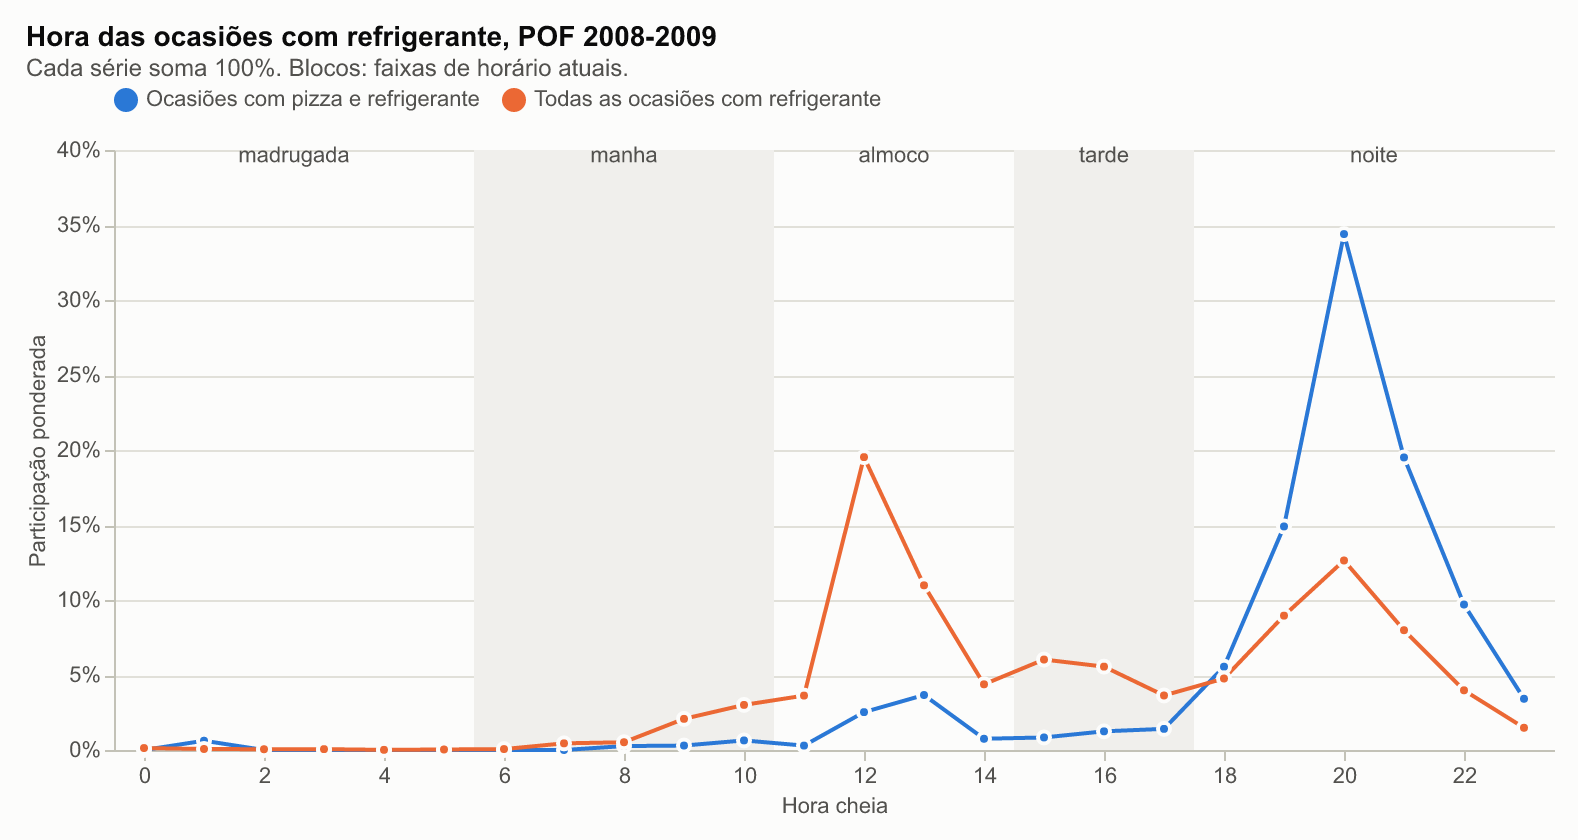

In [4]:
com_refri = ocasioes[ocasioes["tem_refri"]]
pizza_refri = com_refri[com_refri["tem_pizza"]]


def distribuicao_por_hora(df: pd.DataFrame) -> pd.Series:
    soma = df.groupby("hora")["peso_final"].sum().reindex(range(24), fill_value=0.0)
    return soma / soma.sum()


por_hora = pd.DataFrame(
    {
        "pizza_refri": distribuicao_por_hora(pizza_refri),
        "refri": distribuicao_por_hora(com_refri),
        "pizza_refri_contagem": pizza_refri.groupby("hora").size().reindex(range(24), fill_value=0),
        "refri_contagem": com_refri.groupby("hora").size().reindex(range(24), fill_value=0),
    }
).rename_axis("hora")
FAIXA_DA_HORA = {h: nome for nome, faixa in FAIXAS_HORARIO.items() for h in faixa}
por_hora["faixa"] = [FAIXA_DA_HORA[h] for h in por_hora.index]

SERIES_HORA = {
    "pizza_refri": "Ocasiões com pizza e refrigerante",
    "refri": "Todas as ocasiões com refrigerante",
}
longo = (
    por_hora[list(SERIES_HORA)]
    .reset_index()
    .melt("hora", var_name="serie", value_name="participacao")
    .assign(serie=lambda d: d["serie"].map(SERIES_HORA))
)
faixas = pd.DataFrame(
    [
        {
            "faixa": nome,
            "inicio": f.start - 0.5,
            "fim": f.stop - 0.5,
            "meio": (f.start + f.stop - 1) / 2,
            "par": i % 2,
        }
        for i, (nome, f) in enumerate(FAIXAS_HORARIO.items())
    ]
)
topo = float(longo["participacao"].max()) * 1.12
blocos = (
    alt.Chart(faixas)
    .mark_rect(color=NEUTRO)
    .encode(
        x="inicio:Q",
        x2="fim:Q",
        opacity=alt.Opacity("par:N", scale=alt.Scale(range=[0, 1]), legend=None),
    )
)
rotulos_faixa = (
    alt.Chart(faixas.assign(y=topo))
    .mark_text(color=TINTA_2, fontSize=11, baseline="top", dy=-14)
    .encode(x="meio:Q", y="y:Q", text="faixa:N")
)
cores_hora = alt.Scale(domain=list(SERIES_HORA.values()), range=[AZUL, LARANJA])
linhas_hora = (
    alt.Chart(longo)
    .mark_line(point=alt.OverlayMarkDef(size=36, filled=True, stroke=SUPERFICIE, strokeWidth=2))
    .encode(
        x=alt.X(
            "hora:Q",
            title="Hora cheia",
            scale=alt.Scale(domain=[-0.5, 23.5], nice=False),
            axis=alt.Axis(values=list(range(24)), grid=False),
        ),
        y=alt.Y(
            "participacao:Q",
            title="Participação ponderada",
            axis=alt.Axis(format=".0%"),
            scale=alt.Scale(domain=[0, topo]),
        ),
        color=alt.Color("serie:N", scale=cores_hora, title=None),
    )
)
(blocos + linhas_hora + rotulos_faixa).properties(
    width=720,
    height=300,
    title=alt.Title(
        "Hora das ocasiões com refrigerante, POF 2008-2009",
        subtitle="Cada série soma 100%. Blocos: faixas de horário atuais.",
    ),
)

In [5]:
MINIMO_PICO = 0.03  # participação mínima para uma hora contar como pico


def picos(serie: pd.Series) -> list[int]:
    """Horas com participação acima das duas vizinhas e de pelo menos MINIMO_PICO."""
    v = serie.to_numpy()
    return [
        h
        for h in range(24)
        if v[h] >= MINIMO_PICO
        and v[h] > (v[h - 1] if h > 0 else 0)
        and v[h] > (v[h + 1] if h < 23 else 0)
    ]


def corte(serie: pd.Series, h: int) -> dict[str, Any]:
    """Um pico é cortado se uma hora vizinha de outra faixa tem ao menos metade da sua massa."""
    vizinhas = [x for x in (h - 1, h + 1) if 0 <= x <= 23 and FAIXA_DA_HORA[x] != FAIXA_DA_HORA[h]]
    maior = max((float(serie[x]) for x in vizinhas), default=0.0)
    return {
        "hora": h,
        "faixa": FAIXA_DA_HORA[h],
        "participacao": round(float(serie[h]), 4),
        "vizinha_de_outra_faixa": vizinhas,
        "maior_vizinha_de_outra_faixa": round(maior, 4),
        "cortado": maior >= 0.5 * float(serie[h]),
    }


analise_picos = {
    nome: [corte(por_hora[nome], h) for h in picos(por_hora[nome])] for nome in SERIES_HORA
}
massa_por_faixa = por_hora.groupby("faixa")[list(SERIES_HORA)].sum().reindex(ORDEM_FAIXAS)
hora_pico = {nome: int(por_hora[nome].idxmax()) for nome in SERIES_HORA}
algum_corte = any(p["cortado"] for lista in analise_picos.values() for p in lista)

positivos_faixa = {
    "y_pizza_refri_celulas": celulas.groupby("faixa_horario")["y_pizza_refri"]
    .sum()
    .reindex(ORDEM_FAIXAS)
    .astype(int)
    .to_dict(),
    "y_guarana_ocasioes_refri": refri.groupby("faixa_horario")["y_guarana"]
    .sum()
    .reindex(ORDEM_FAIXAS)
    .astype(int)
    .to_dict(),
    "ocasioes_refri_contagem": refri.groupby("faixa_horario")
    .size()
    .reindex(ORDEM_FAIXAS)
    .astype(int)
    .to_dict(),
}
eda["horario"] = {
    "hora_pico": hora_pico,
    "participacao_por_faixa": {
        nome: {f: round(float(v), 4) for f, v in massa_por_faixa[nome].items()}
        for nome in SERIES_HORA
    },
    "picos": analise_picos,
    "criterio_de_corte": (
        f"pico = hora com participação >= {MINIMO_PICO} e acima das duas vizinhas; cortado se a "
        "vizinha de outra faixa tem ao menos metade da participação do pico"
    ),
    "alguma_fronteira_corta_pico": algum_corte,
    "positivos_por_faixa": positivos_faixa,
    "sugestao_de_fronteira": None,
}
cortados = [(nome, p) for nome, lista in analise_picos.items() for p in lista if p["cortado"]]
cortados_pizza = [p for nome, p in cortados if nome == "pizza_refri"]
if cortados and not cortados_pizza:
    eda["horario"]["observacao"] = (
        "Só a série de todas as ocasiões com refrigerante tem pico dividido entre faixas: "
        + "; ".join(
            f"{p['hora']}h ({pct(p['participacao'])}) com a vizinha "
            + ", ".join(
                f"{x}h ({pct(por_hora.loc[x, nome])}, faixa {FAIXA_DA_HORA[x]})"
                for x in p["vizinha_de_outra_faixa"]
            )
            + " em outra faixa"
            for nome, p in cortados
        )
        + ". A série do alvo da parte 1 não tem pico cortado; nenhuma mudança é sugerida."
    )

tabela_faixas = massa_por_faixa.rename(columns=SERIES_HORA).map(pct)
tabela_faixas["positivos y_pizza_refri (contagem)"] = pd.Series(
    positivos_faixa["y_pizza_refri_celulas"]
)
tabela_faixas

,Ocasiões com pizza e refrigerante,Todas as ocasiões com refrigerante,positivos y_pizza_refri (contagem)
faixa,,,
madrugada,"0,6%","0,4%",1
manha,"1,2%","6,1%",17
almoco,"7,2%","38,5%",42
tarde,"3,5%","15,2%",38
noite,"87,5%","39,8%",556


In [6]:
fp = massa_por_faixa["pizza_refri"]
descricao_picos = "; ".join(
    f"{SERIES_HORA[nome].lower()}: "
    + ", ".join(f"{p['hora']}h ({pct(p['participacao'])}, faixa {p['faixa']})" for p in lista)
    for nome, lista in analise_picos.items()
)
leitura(
    f"A hora de pico das ocasiões com pizza e refrigerante é {hora_pico['pizza_refri']}h, e a "
    f"faixa noite reúne {pct(fp['noite'])} delas; nas ocasiões com refrigerante em geral o pico é "
    f"{hora_pico['refri']}h. Picos locais ({descricao_picos}). "
    + (
        "Nenhuma fronteira corta um pico: em todos eles a hora vizinha que cai em outra faixa tem "
        "menos da metade da participação do pico."
        if not algum_corte
        else "Picos divididos entre faixas (a vizinha de outra faixa tem ao menos metade da "
        "participação do pico): "
        + "; ".join(
            f"{p['hora']}h em {SERIES_HORA[nome].lower()} ({pct(p['participacao'])}), com "
            + ", ".join(
                f"{x}h na faixa {FAIXA_DA_HORA[x]} ({pct(por_hora.loc[x, nome])})"
                for x in p["vizinha_de_outra_faixa"]
            )
            for nome, p in cortados
        )
        + (
            ". Nas ocasiões com pizza e refrigerante nenhum pico é cortado."
            if not cortados_pizza
            else "."
        )
    )
)

**Leitura.** A hora de pico das ocasiões com pizza e refrigerante é 20h, e a faixa noite reúne 87,5% delas; nas ocasiões com refrigerante em geral o pico é 12h. Picos locais (ocasiões com pizza e refrigerante: 13h (3,7%, faixa almoco), 20h (34,4%, faixa noite); todas as ocasiões com refrigerante: 12h (19,5%, faixa almoco), 15h (6,0%, faixa tarde), 20h (12,6%, faixa noite)). Picos divididos entre faixas (a vizinha de outra faixa tem ao menos metade da participação do pico): 15h em todas as ocasiões com refrigerante (6,0%), com 14h na faixa almoco (4,4%). Nas ocasiões com pizza e refrigerante nenhum pico é cortado.

## 2. Taxas por variável de contexto

Taxa ponderada de cada alvo por categoria de cada variável de `COLUNAS_CONTEXTO`, com
intervalo de 95%. Idade e renda aparecem nas faixas de `occasion.eda.descritivas`; o número de
moradores é agrupado em 7 ou mais. A linha vertical é a taxa geral.

Em 2008-2009, `local` vem da "fonte do alimento" (obtido dentro ou fora do domicílio), não do
local da refeição: uma pizza comprada fora e comida em casa pode aparecer como `fora_de_casa`.

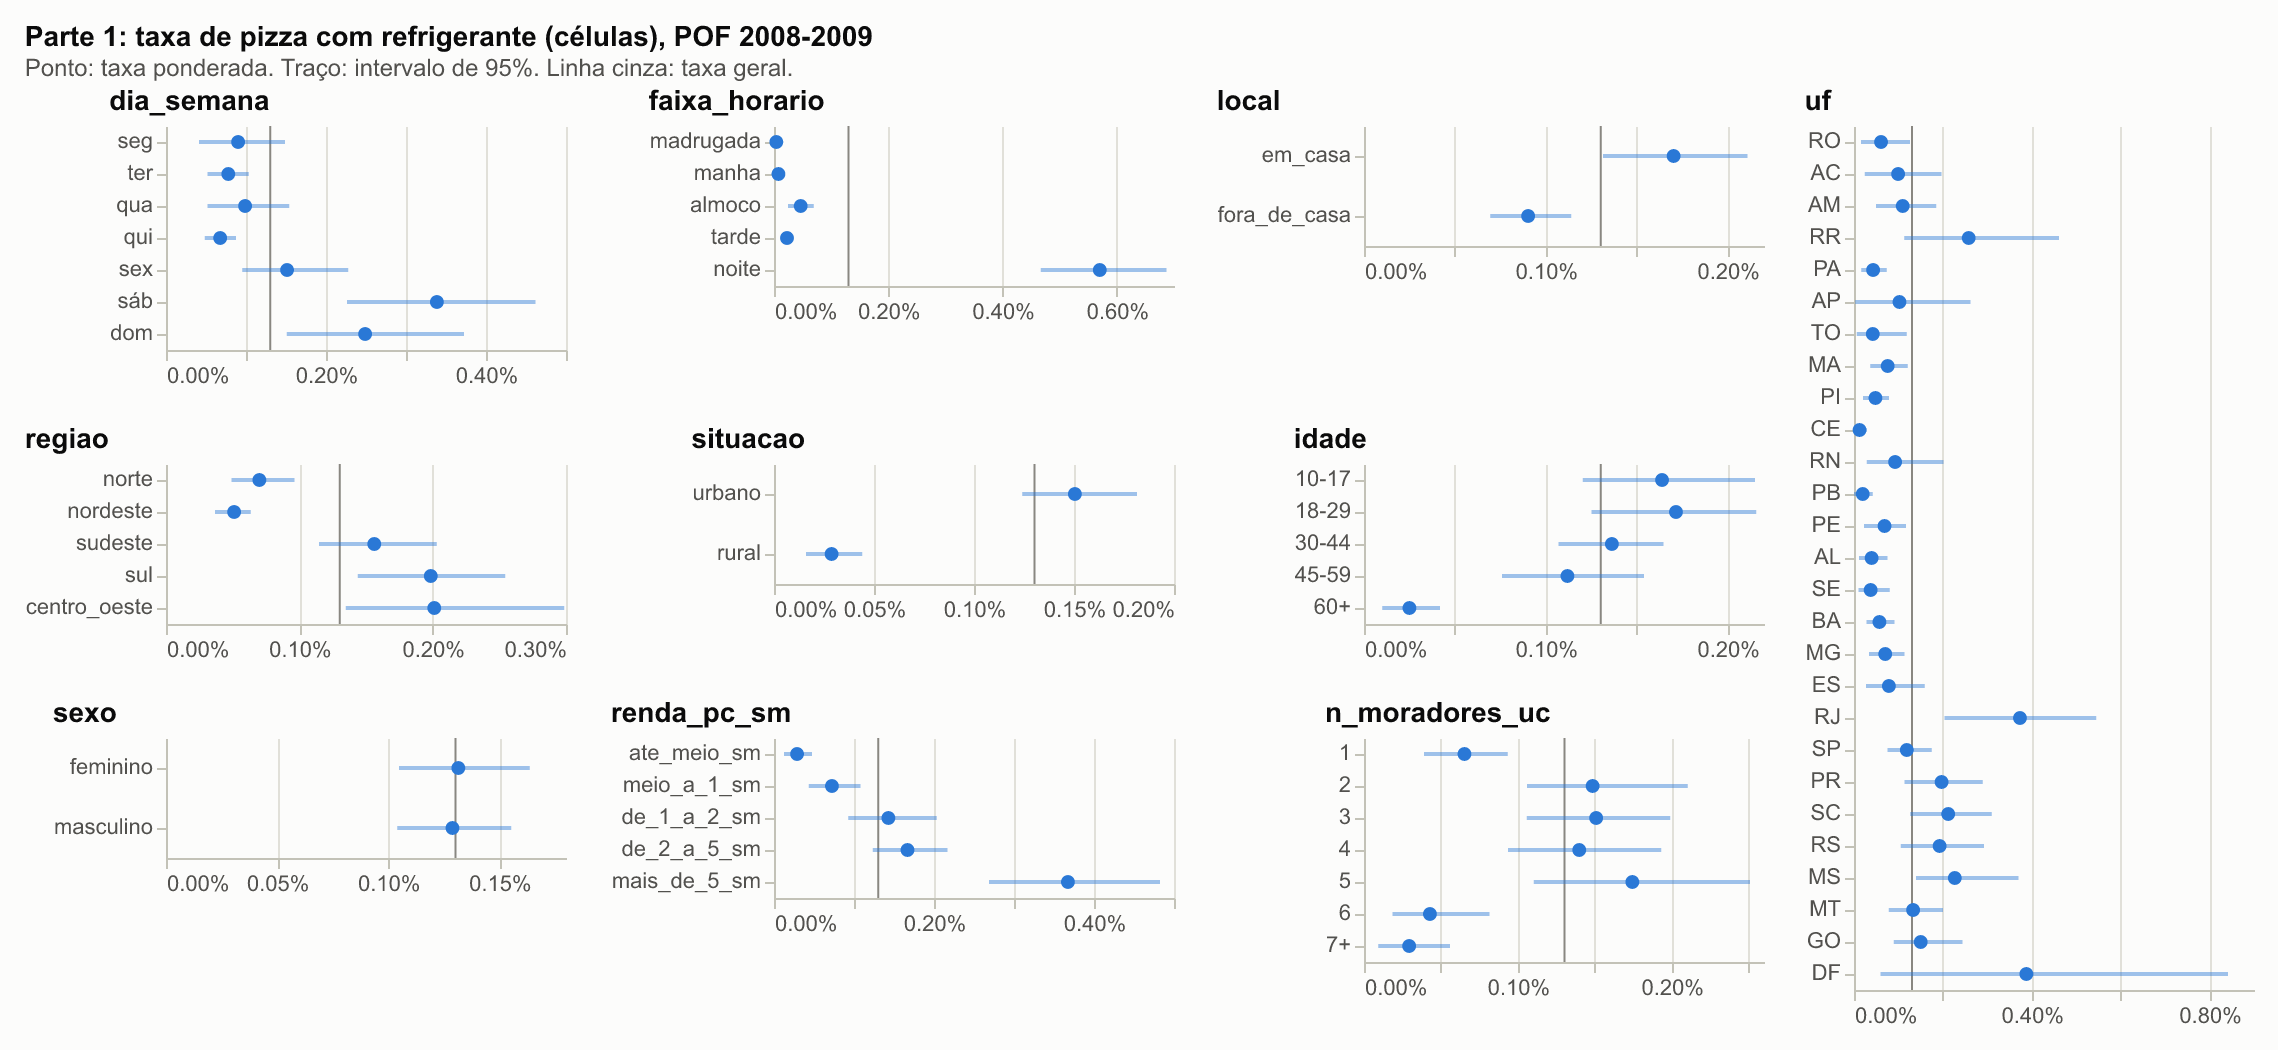

In [7]:
VARIAVEIS = {
    "dia_semana": ("dia", DIAS),
    "faixa_horario": ("faixa_horario", ORDEM_FAIXAS),
    "local": ("local", ["em_casa", "fora_de_casa"]),
    "uf": ("uf_sigla", list(CODIGO_UF)),
    "regiao": ("regiao", ["norte", "nordeste", "sudeste", "sul", "centro_oeste"]),
    "situacao": ("situacao", ["urbano", "rural"]),
    "idade": ("faixa_idade", list(FAIXAS_ETARIAS)),
    "sexo": ("sexo", ["feminino", "masculino"]),
    "renda_pc_sm": ("faixa_renda", ORDEM_RENDA),
    "n_moradores_uc": ("moradores", ORDEM_MORADORES),
}
assert list(VARIAVEIS) == COLUNAS_CONTEXTO

PARTES = {
    "ocasiao": {
        "base": celulas,
        "alvo": "y_pizza_refri",
        "nome": "pizza com refrigerante (células)",
        "casas": 2,
        "formato": ".2%",
    },
    "preferencia": {
        "base": refri,
        "alvo": "y_guarana",
        "nome": "guaraná nas ocasiões com refrigerante",
        "casas": 1,
        "formato": ".0%",
    },
}


def taxa_geral(base: pd.DataFrame, alvo: str) -> float:
    return float((base["peso_final"] * base[alvo]).sum() / base["peso_final"].sum())


taxas_por_variavel: dict[str, pd.DataFrame] = {}
for parte, cfg in PARTES.items():
    pedacos = []
    for variavel, (coluna, ordem) in VARIAVEIS.items():
        t = taxas(
            cfg["base"].assign(**{coluna: cfg["base"][coluna].astype(str)}),
            cfg["alvo"],
            [coluna],
            b=B,
        )
        t = t.rename(columns={coluna: "categoria"}).assign(variavel=variavel)
        t["ordem"] = t["categoria"].map({c: i for i, c in enumerate(ordem)})
        pedacos.append(t.sort_values("ordem"))
    taxas_por_variavel[parte] = pd.concat(pedacos, ignore_index=True)


def painel_taxas(
    tabela: pd.DataFrame, variavel: str, geral: float, cor: str, formato: str
) -> alt.LayerChart:
    dados = tabela[tabela["variavel"] == variavel]
    ordem = dados.sort_values("ordem")["categoria"].tolist()
    y = alt.Y("categoria:N", sort=ordem, title=None)
    barras = (
        alt.Chart(dados)
        .mark_rule(color=cor, strokeWidth=2, opacity=0.45)
        .encode(
            y=y,
            x=alt.X("ic_inf:Q", title=None, axis=alt.Axis(format=formato, tickCount=4)),
            x2="ic_sup:Q",
        )
    )
    pontos = (
        alt.Chart(dados)
        .mark_point(color=cor, filled=True, size=48, opacity=1)
        .encode(y=y, x="taxa:Q")
    )
    referencia = (
        alt.Chart(pd.DataFrame({"geral": [geral]}))
        .mark_rule(color=TINTA_FRACA, strokeWidth=1)
        .encode(x="geral:Q")
    )
    return (referencia + barras + pontos).properties(
        width=200, height=max(60, 16 * len(dados)), title=variavel
    )


def grade_de_taxas(parte: str, cor: str) -> alt.ConcatChart:
    cfg = PARTES[parte]
    geral = taxa_geral(cfg["base"], cfg["alvo"])
    paineis = [
        painel_taxas(taxas_por_variavel[parte], v, geral, cor, cfg["formato"])
        for v in VARIAVEIS
        if v != "uf"
    ]
    uf = painel_taxas(taxas_por_variavel[parte], "uf", geral, cor, cfg["formato"])
    return alt.hconcat(alt.concat(*paineis, columns=3), uf).properties(
        title=alt.Title(
            f"Parte {1 if parte == 'ocasiao' else 2}: taxa de {cfg['nome']}, POF 2008-2009",
            subtitle="Ponto: taxa ponderada. Traço: intervalo de 95%. Linha cinza: taxa geral.",
        )
    )


grade_de_taxas("ocasiao", AZUL)

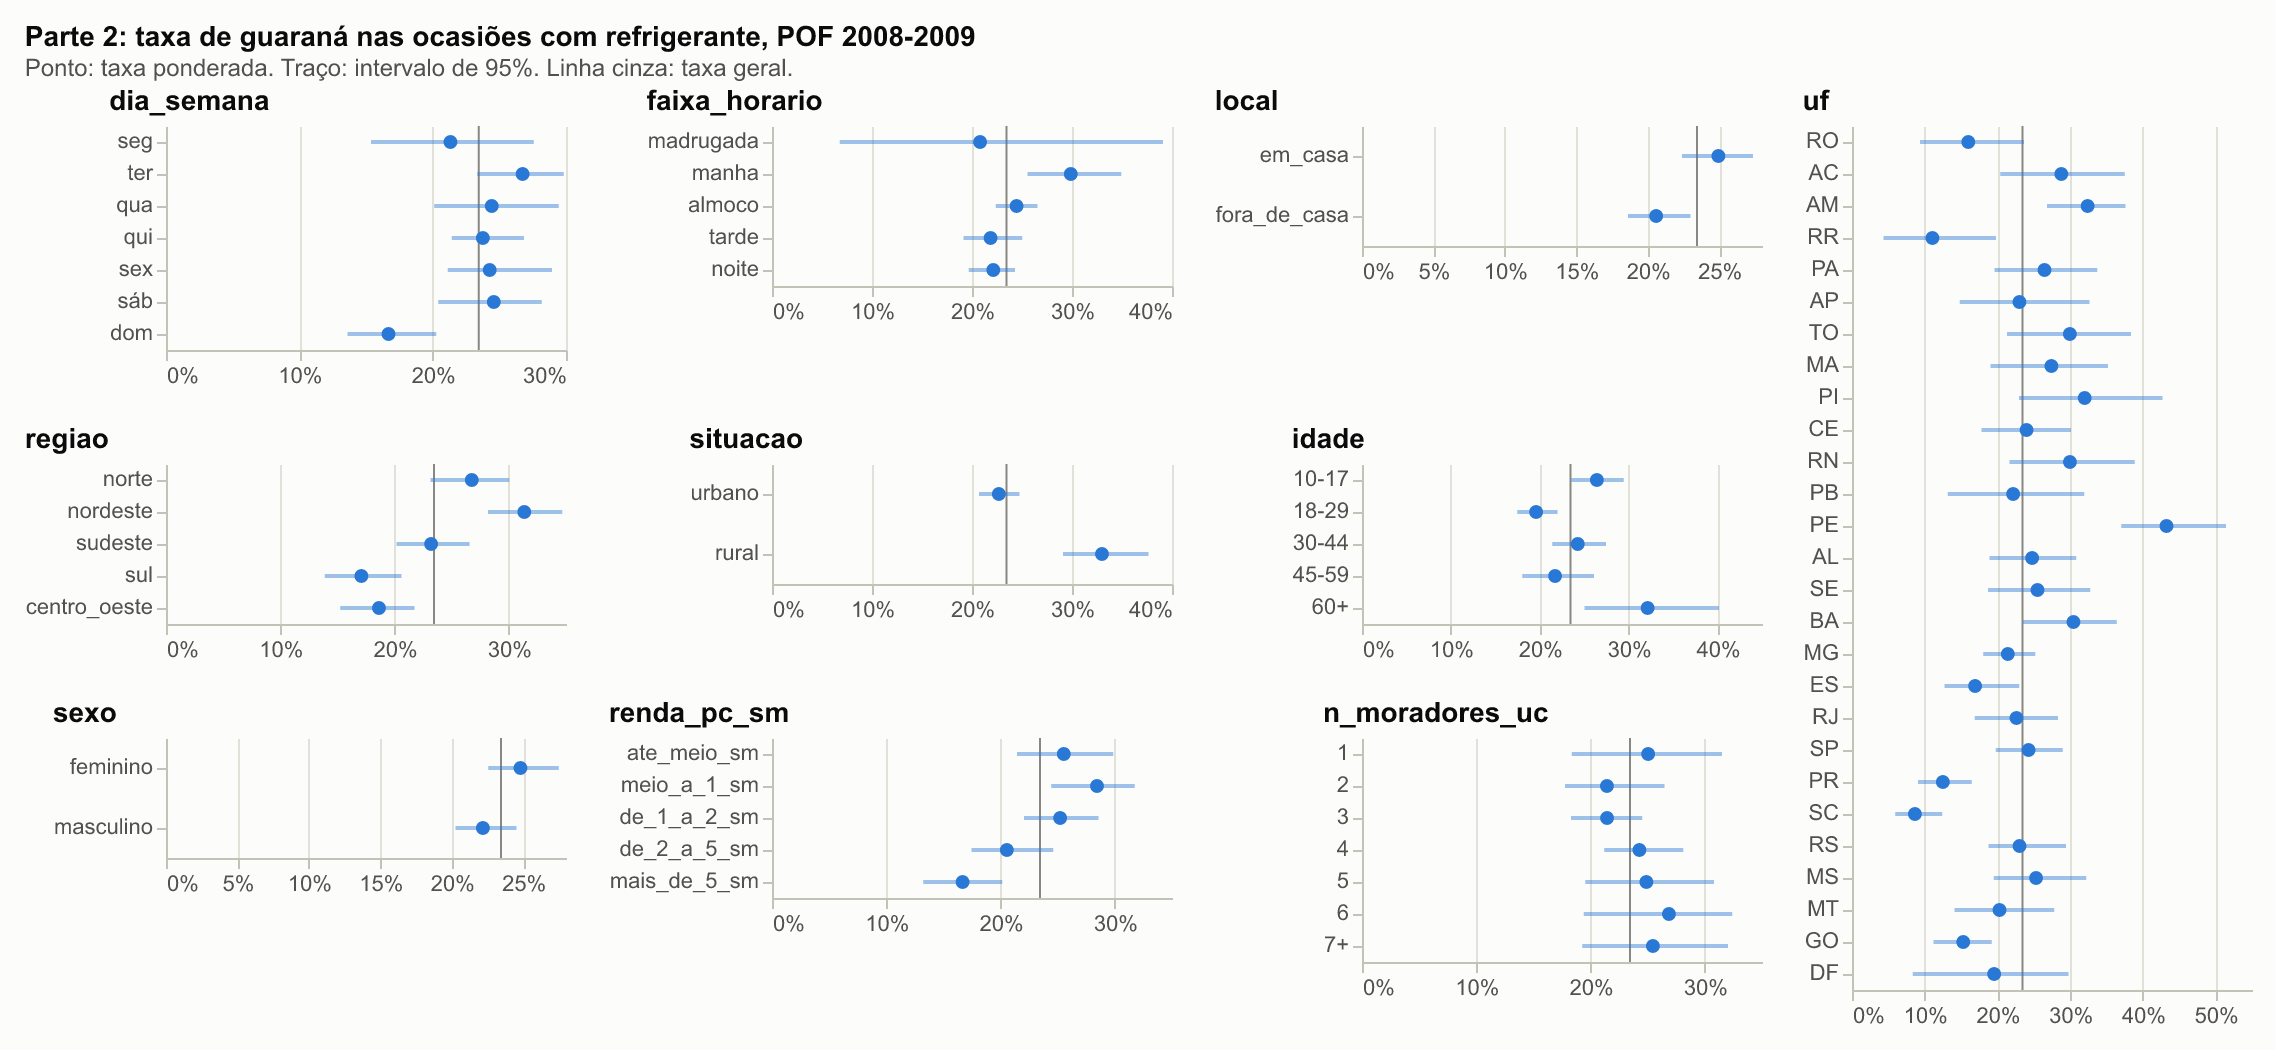

In [8]:
grade_de_taxas("preferencia", AZUL)

In [9]:
MIN_POSITIVOS = 20  # categorias com menos positivos ficam fora da amplitude (ruído)


def amplitudes(parte: str) -> pd.DataFrame:
    t = taxas_por_variavel[parte]
    t = t[t["positivos"] >= MIN_POSITIVOS]
    linhas = []
    for variavel, g in t.groupby("variavel", sort=False):
        maior, menor = g.loc[g["taxa"].idxmax()], g.loc[g["taxa"].idxmin()]
        linhas.append(
            {
                "variavel": variavel,
                "maior": maior["categoria"],
                "taxa_maior": maior["taxa"],
                "menor": menor["categoria"],
                "taxa_menor": menor["taxa"],
                "razao": maior["taxa"] / menor["taxa"],
                "intervalos_separados": bool(maior["ic_inf"] > menor["ic_sup"]),
            }
        )
    return pd.DataFrame(linhas).sort_values("razao", ascending=False, ignore_index=True)


amp = {parte: amplitudes(parte) for parte in PARTES}
eda["taxas_por_variavel"] = {
    parte: {
        "taxa_geral": round(taxa_geral(cfg["base"], cfg["alvo"]), 5),
        "amplitude": amp[parte].round(5).to_dict(orient="records"),
        "tabela": taxas_por_variavel[parte]
        .drop(columns="ordem")
        .round(5)
        .to_dict(orient="records"),
    }
    for parte, cfg in PARTES.items()
}


def frase_amplitude(parte: str, n: int = 3) -> str:
    k = PARTES[parte]["casas"]
    return "; ".join(
        f"{r.variavel} ({pct(r.taxa_maior, k)} em {r.maior} contra {pct(r.taxa_menor, k)} em "
        f"{r.menor})"
        for r in amp[parte].head(n).itertuples()
    )


sem_separacao = {
    p: amp[p].loc[~amp[p]["intervalos_separados"], "variavel"].tolist() for p in PARTES
}
leitura(
    f"Na ocasião (taxa geral {pct(taxa_geral(celulas, 'y_pizza_refri'), 2)} por célula), as maiores "
    f"diferenças entre categorias estão em {frase_amplitude('ocasiao')}. Na preferência (taxa "
    f"geral {pct(taxa_geral(refri, 'y_guarana'))}), estão em {frase_amplitude('preferencia')}. "
    f"Variáveis em que os intervalos da maior e da menor categoria se sobrepõem: ocasião, "
    f"{', '.join(sem_separacao['ocasiao']) or 'nenhuma'}; preferência, "
    f"{', '.join(sem_separacao['preferencia']) or 'nenhuma'}. Categorias com menos de "
    f"{MIN_POSITIVOS} positivos ficam fora dessa comparação. O maior e o menor entre muitas "
    f"categorias (as {len(VARIAVEIS['uf'][1])} UFs, por exemplo) exageram a amplitude: com "
    "muitas categorias, os extremos tendem a ser os mais ruidosos."
)

**Leitura.** Na ocasião (taxa geral 0,13% por célula), as maiores diferenças entre categorias estão em faixa_horario (0,57% em noite contra 0,02% em tarde); renda_pc_sm (0,37% em mais_de_5_sm contra 0,03% em ate_meio_sm); idade (0,17% em 18-29 contra 0,02% em 60+). Na preferência (taxa geral 23,5%), estão em uf (43,2% em PE contra 8,7% em SC); regiao (31,3% em nordeste contra 17,1% em sul); renda_pc_sm (28,4% em meio_a_1_sm contra 16,7% em mais_de_5_sm). Variáveis em que os intervalos da maior e da menor categoria se sobrepõem: ocasião, sexo; preferência, n_moradores_uc, local, sexo. Categorias com menos de 20 positivos ficam fora dessa comparação. O maior e o menor entre muitas categorias (as 27 UFs, por exemplo) exageram a amplitude: com muitas categorias, os extremos tendem a ser os mais ruidosos.

## 3. Curvas de idade e de renda

As mesmas duas taxas por faixas de 5 anos de idade e por décimos ponderados da renda por
pessoa. A pergunta é se a relação é reta na escala em que o modelo recebe a variável: idade
linear e `log1p(renda_pc_sm)`.

Para cada uma das quatro curvas, uma logística ponderada de uma variável só é ajustada no
alvo (a "reta" em log-chances). Por faixa, o desvio é a diferença, em log-chances, entre a
taxa observada e a taxa que a reta ajustada dá à faixa. O intervalo do desvio vem do bootstrap
de setores pareado: cada réplica usa os mesmos multiplicadores na taxa observada e no
reajuste da reta. O ajuste usa as somas por idade em anos (exato) e, na renda, por
centésimos ponderados com a média de `log1p(renda)` de cada centésimo (aproximação).

Desvio que exclui zero numa faixa isolada pode ser acaso: com 95%, cerca de 1 em 20 faixas
exclui zero mesmo quando a reta é a verdade.

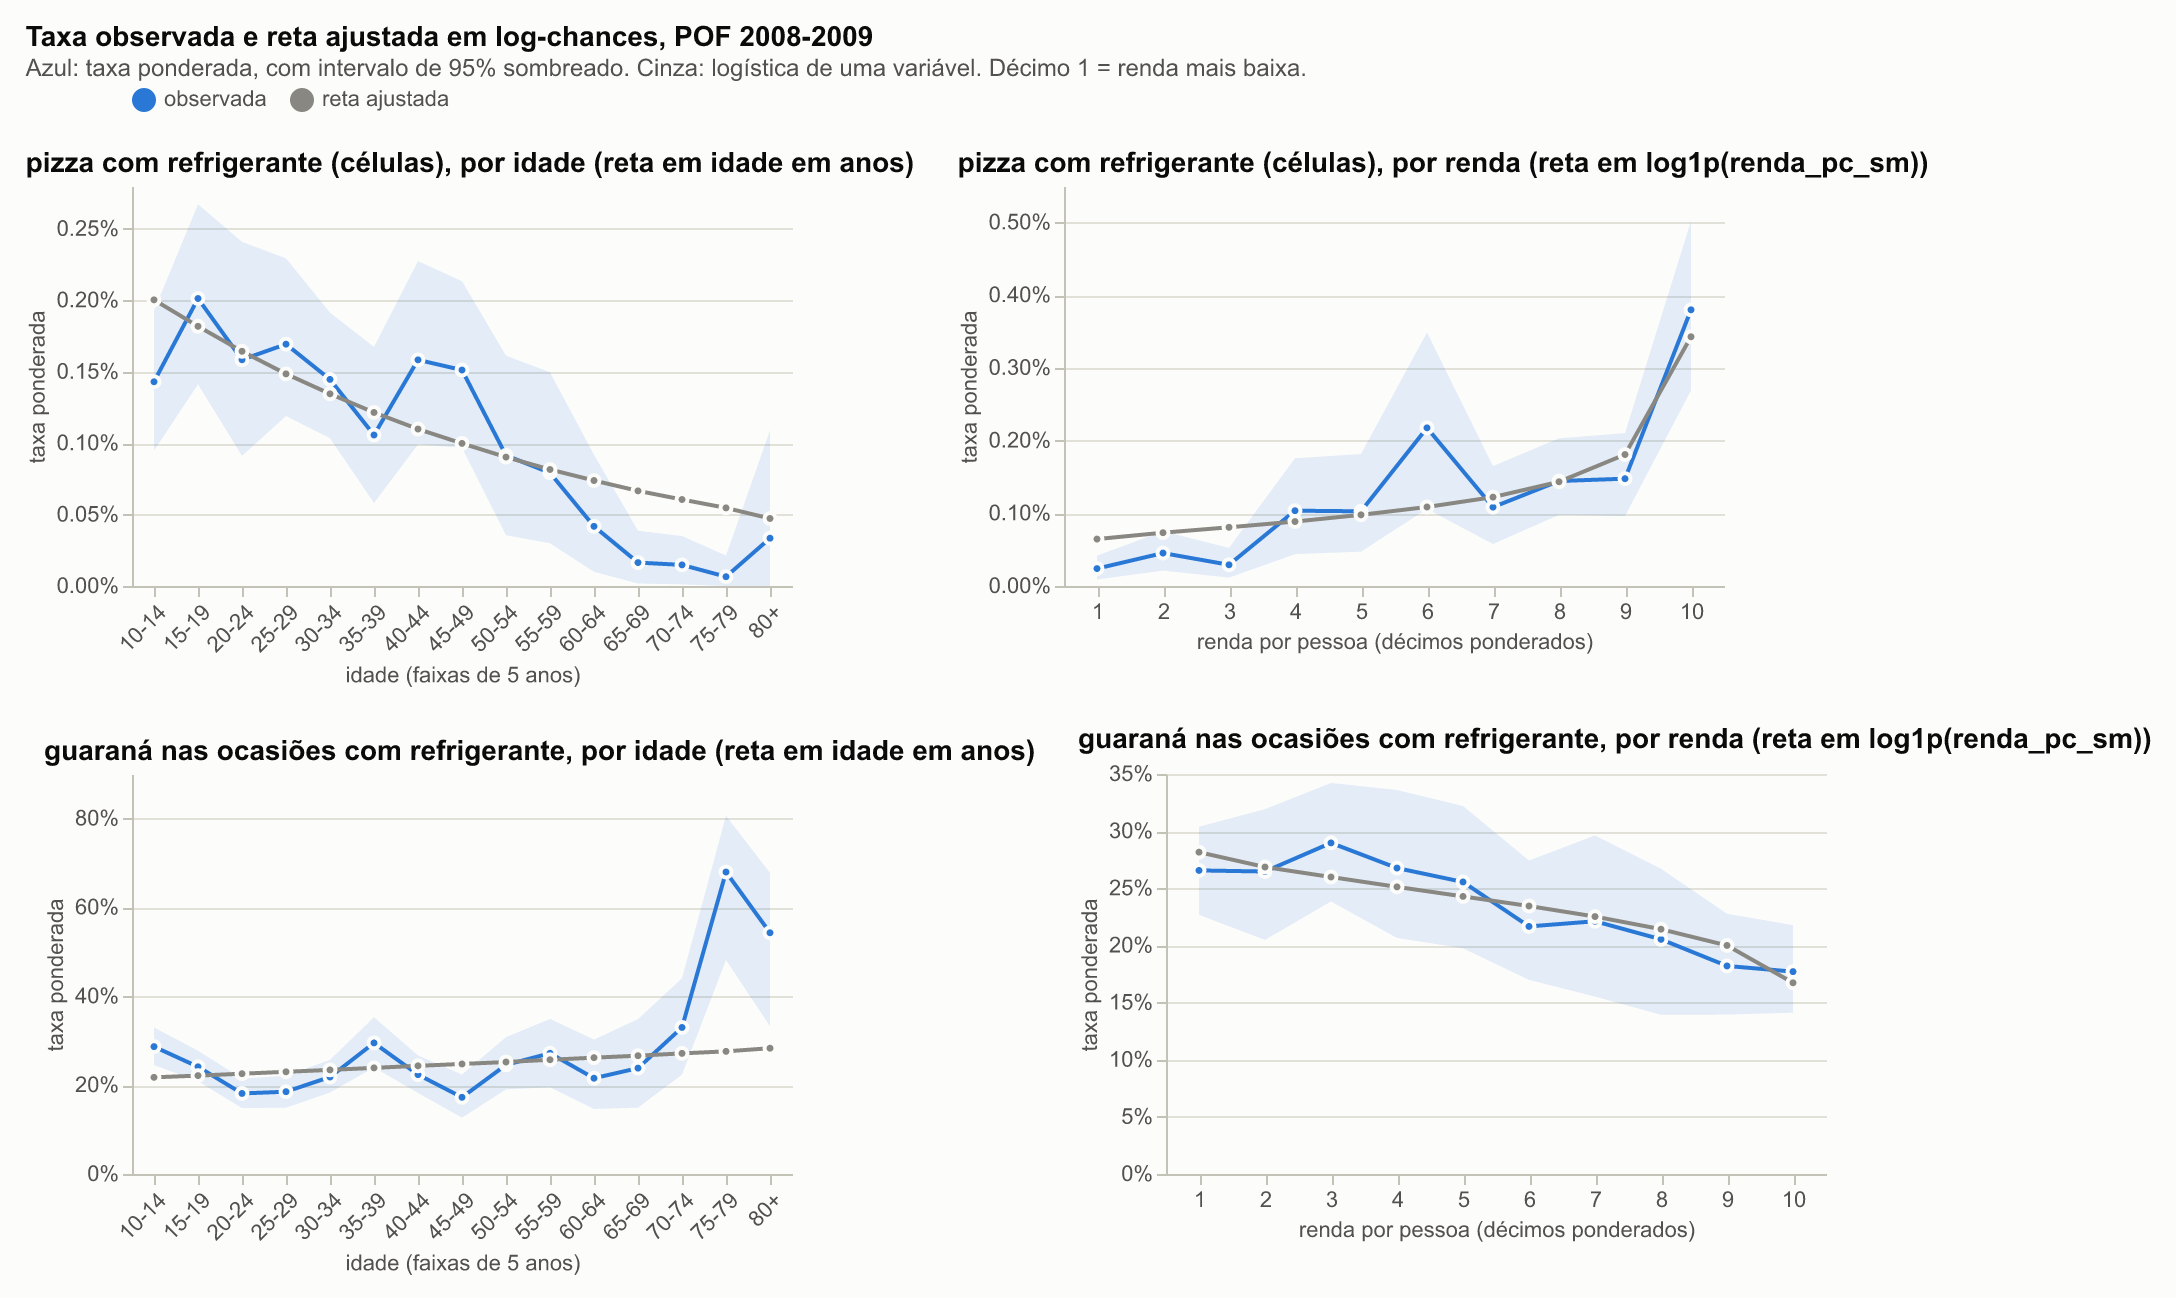

In [10]:
CORTES_IDADE = list(range(10, 85, 5))  # 10-14, ..., 75-79 e 80+
ORDEM_IDADE_5 = [f"{i}-{i + 4}" for i in CORTES_IDADE[:-1]] + ["80+"]
ORDEM_DECIS = [str(i) for i in range(1, 11)]
E_IDADE, E_RENDA = "idade (faixas de 5 anos)", "renda por pessoa (décimos ponderados)"
ESCALA = {E_IDADE: "idade em anos", E_RENDA: "log1p(renda_pc_sm)"}


def faixa_de_5_anos(idade: np.ndarray) -> np.ndarray:
    """Índice da faixa de 5 anos em ORDEM_IDADE_5 (80 ou mais vai para a última)."""
    return (np.clip(idade, 10, 80) - 10) // 5


def sigmoide(z: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-z))


def logit_bruto(p: np.ndarray) -> np.ndarray:
    """Log-chances sem corte: taxa 0 ou 1 vira NaN (a réplica não define o desvio)."""
    with np.errstate(divide="ignore", invalid="ignore"):
        z = np.log(p / (1 - p))
    return np.where(np.isfinite(z), z, np.nan)


def ajustar_reta(x: np.ndarray, w: np.ndarray, wy: np.ndarray, inicio: np.ndarray) -> np.ndarray:
    """Logística ponderada de uma variável em dados agrupados, por Newton-Raphson."""
    X = np.column_stack([np.ones_like(x), x])
    beta = inicio.astype(float).copy()
    for _ in range(100):
        p = sigmoide(X @ beta)
        gradiente = X.T @ (wy - w * p)
        hessiana = (X * (w * p * (1 - p))[:, None]).T @ X
        passo = np.linalg.solve(hessiana, gradiente)
        beta = beta + passo
        if np.max(np.abs(passo)) < 1e-10:
            break
    return beta


def unidades(base: pd.DataFrame, eixo: str) -> tuple[np.ndarray, np.ndarray, np.ndarray, list]:
    """Unidade fina de cada linha, valor de x da unidade, faixa exibida da unidade e rótulos."""
    if eixo == E_IDADE:
        idade = base["idade"].to_numpy()
        valores = np.arange(idade.min(), idade.max() + 1)
        fina = idade - idade.min()
        return fina, valores.astype(float), faixa_de_5_anos(valores), ORDEM_IDADE_5
    renda = base["renda_pc_sm"]
    cortes = quantis_ponderados(renda, base["peso_final"], np.arange(1, 100) / 100)
    fina = np.searchsorted(cortes, renda.to_numpy(), side="right")  # 0 a 99
    w = base["peso_final"].to_numpy()
    lx = np.log1p(renda.to_numpy())
    soma_w = np.bincount(fina, weights=w, minlength=100)
    x = np.divide(
        np.bincount(fina, weights=w * lx, minlength=100),
        soma_w,
        out=np.zeros(100),
        where=soma_w > 0,
    )
    return fina, x, np.arange(100) // 10, ORDEM_DECIS


def curva_contra_reta(parte: str, eixo: str, b: int = B_DESTAQUE) -> dict[str, Any]:
    cfg = PARTES[parte]
    base, alvo = cfg["base"], cfg["alvo"]
    fina, x, faixa_da_fina, rotulos = unidades(base, eixo)
    n_fina = len(x)
    setores, uf = setores_e_uf(base)
    setor = np.searchsorted(setores, base["cod_upa"].to_numpy())
    w = base["peso_final"].to_numpy(dtype=float)
    y = base[alvo].to_numpy(dtype=float)
    chave = setor * n_fina + fina
    tamanho = len(setores) * n_fina
    W = np.bincount(chave, weights=w, minlength=tamanho).reshape(len(setores), n_fina)
    WY = np.bincount(chave, weights=w * y, minlength=tamanho).reshape(len(setores), n_fina)
    media, desvio_padrao = float(np.average(x, weights=W.sum(0))), float(np.std(x))
    xp = (x - media) / desvio_padrao
    n_faixas = len(rotulos)

    def calcular(m: np.ndarray, inicio: np.ndarray) -> tuple[np.ndarray, ...]:
        wf, wyf = m @ W, m @ WY
        beta = ajustar_reta(xp, wf, wyf, inicio)
        pf = sigmoide(beta[0] + beta[1] * xp)
        den = np.bincount(faixa_da_fina, weights=wf, minlength=n_faixas)
        obs = np.bincount(faixa_da_fina, weights=wyf, minlength=n_faixas) / den
        ajustada = np.bincount(faixa_da_fina, weights=wf * pf, minlength=n_faixas) / den
        return beta, obs, ajustada, logit_bruto(obs) - logit_bruto(ajustada)

    geral = float(WY.sum() / W.sum())
    beta, obs, ajustada, desvio = calcular(
        np.ones(len(setores)), np.array([float(logit(geral)), 0.0])
    )
    reps_obs, reps_desvio = [], []
    for m in multiplicadores(setores, uf, b, SEMENTE):
        _, o, _, d = calcular(m.astype(float), beta)
        reps_obs.append(o)
        reps_desvio.append(d)
    reps_obs, reps_desvio = np.array(reps_obs), np.array(reps_desvio)
    q = [2.5, 97.5]
    faixa_da_linha = faixa_da_fina[fina]
    tabela = pd.DataFrame(
        {
            "x": rotulos,
            "pos": range(n_faixas),
            "n": np.bincount(faixa_da_linha, minlength=n_faixas),
            "positivos": np.bincount(faixa_da_linha, weights=y, minlength=n_faixas).astype(int),
            "taxa": obs,
            "ic_inf": np.nanpercentile(reps_obs, q[0], axis=0),
            "ic_sup": np.nanpercentile(reps_obs, q[1], axis=0),
            "taxa_ajustada": ajustada,
            "desvio": desvio,
            "desvio_ic_inf": np.nanpercentile(reps_desvio, q[0], axis=0),
            "desvio_ic_sup": np.nanpercentile(reps_desvio, q[1], axis=0),
            "b_validas": np.isfinite(reps_desvio).sum(0),
        }
    )
    tabela["exclui_zero"] = (tabela["desvio_ic_inf"] > 0) | (tabela["desvio_ic_sup"] < 0)
    tabela.loc[tabela["positivos"] == 0, ["ic_inf", "ic_sup", "desvio_ic_inf", "desvio_ic_sup"]] = (
        np.nan
    )
    return {
        "tabela": tabela,
        "escala": ESCALA[eixo],
        "inclinacao_por_desvio_padrao": float(beta[1]),
        "b": b,
    }


curvas = {parte: {eixo: curva_contra_reta(parte, eixo) for eixo in ESCALA} for parte in PARTES}


def grafico_curva(parte: str, eixo: str) -> alt.LayerChart:
    t = curvas[parte][eixo]["tabela"]
    ordem = t["x"].tolist()
    x = alt.X(
        "x:N", sort=ordem, title=eixo, axis=alt.Axis(labelAngle=0 if len(ordem) <= 10 else -45)
    )
    y_fmt = alt.Axis(format=PARTES[parte]["formato"], tickCount=5)
    longo = pd.concat(
        [
            t[["x", "taxa"]].assign(serie="observada"),
            t[["x", "taxa_ajustada"]]
            .rename(columns={"taxa_ajustada": "taxa"})
            .assign(serie=f"reta em {ESCALA[eixo]}"),
        ]
    )
    longo["serie_cor"] = np.where(longo["serie"] == "observada", "observada", "reta ajustada")
    cores = alt.Scale(domain=["observada", "reta ajustada"], range=[AZUL, TINTA_FRACA])
    banda = (
        alt.Chart(t)
        .mark_area(color=AZUL, opacity=0.12)
        .encode(x=x, y=alt.Y("ic_inf:Q", title="taxa ponderada", axis=y_fmt), y2="ic_sup:Q")
    )
    linhas = (
        alt.Chart(longo)
        .mark_line(point=alt.OverlayMarkDef(size=30, stroke=SUPERFICIE, strokeWidth=2))
        .encode(
            x=x,
            y="taxa:Q",
            color=alt.Color("serie_cor:N", scale=cores, title=None),
            order=alt.Order("serie_cor:N"),
        )
    )
    titulo = f"{PARTES[parte]['nome']}, por {eixo.split(' ')[0]} (reta em {ESCALA[eixo]})"
    return (banda + linhas).properties(width=330, height=200, title=titulo)


def grafico_desvio(parte: str, eixo: str) -> alt.LayerChart:
    t = curvas[parte][eixo]["tabela"]
    ordem = t["x"].tolist()
    x = alt.X(
        "x:N", sort=ordem, title=eixo, axis=alt.Axis(labelAngle=0 if len(ordem) <= 10 else -45)
    )
    zero = alt.Chart(pd.DataFrame({"z": [0.0]})).mark_rule(color=EIXO).encode(y="z:Q")
    barras = (
        alt.Chart(t)
        .mark_rule(color=AZUL, strokeWidth=2, opacity=0.5)
        .encode(
            x=x,
            y=alt.Y("desvio_ic_inf:Q", title="desvio da reta (log-chances)"),
            y2="desvio_ic_sup:Q",
        )
    )
    pontos = (
        alt.Chart(t)
        .mark_point(color=AZUL, filled=True, size=48, opacity=1)
        .encode(x=x, y="desvio:Q")
    )
    return (zero + barras + pontos).properties(
        width=330, height=160, title=f"{PARTES[parte]['nome']}, por {eixo.split(' ')[0]}"
    )


alt.vconcat(
    *[alt.hconcat(*[grafico_curva(parte, eixo) for eixo in ESCALA]) for parte in PARTES]
).properties(
    title=alt.Title(
        "Taxa observada e reta ajustada em log-chances, POF 2008-2009",
        subtitle="Azul: taxa ponderada, com intervalo de 95% sombreado. Cinza: logística de uma "
        "variável. Décimo 1 = renda mais baixa.",
    )
)

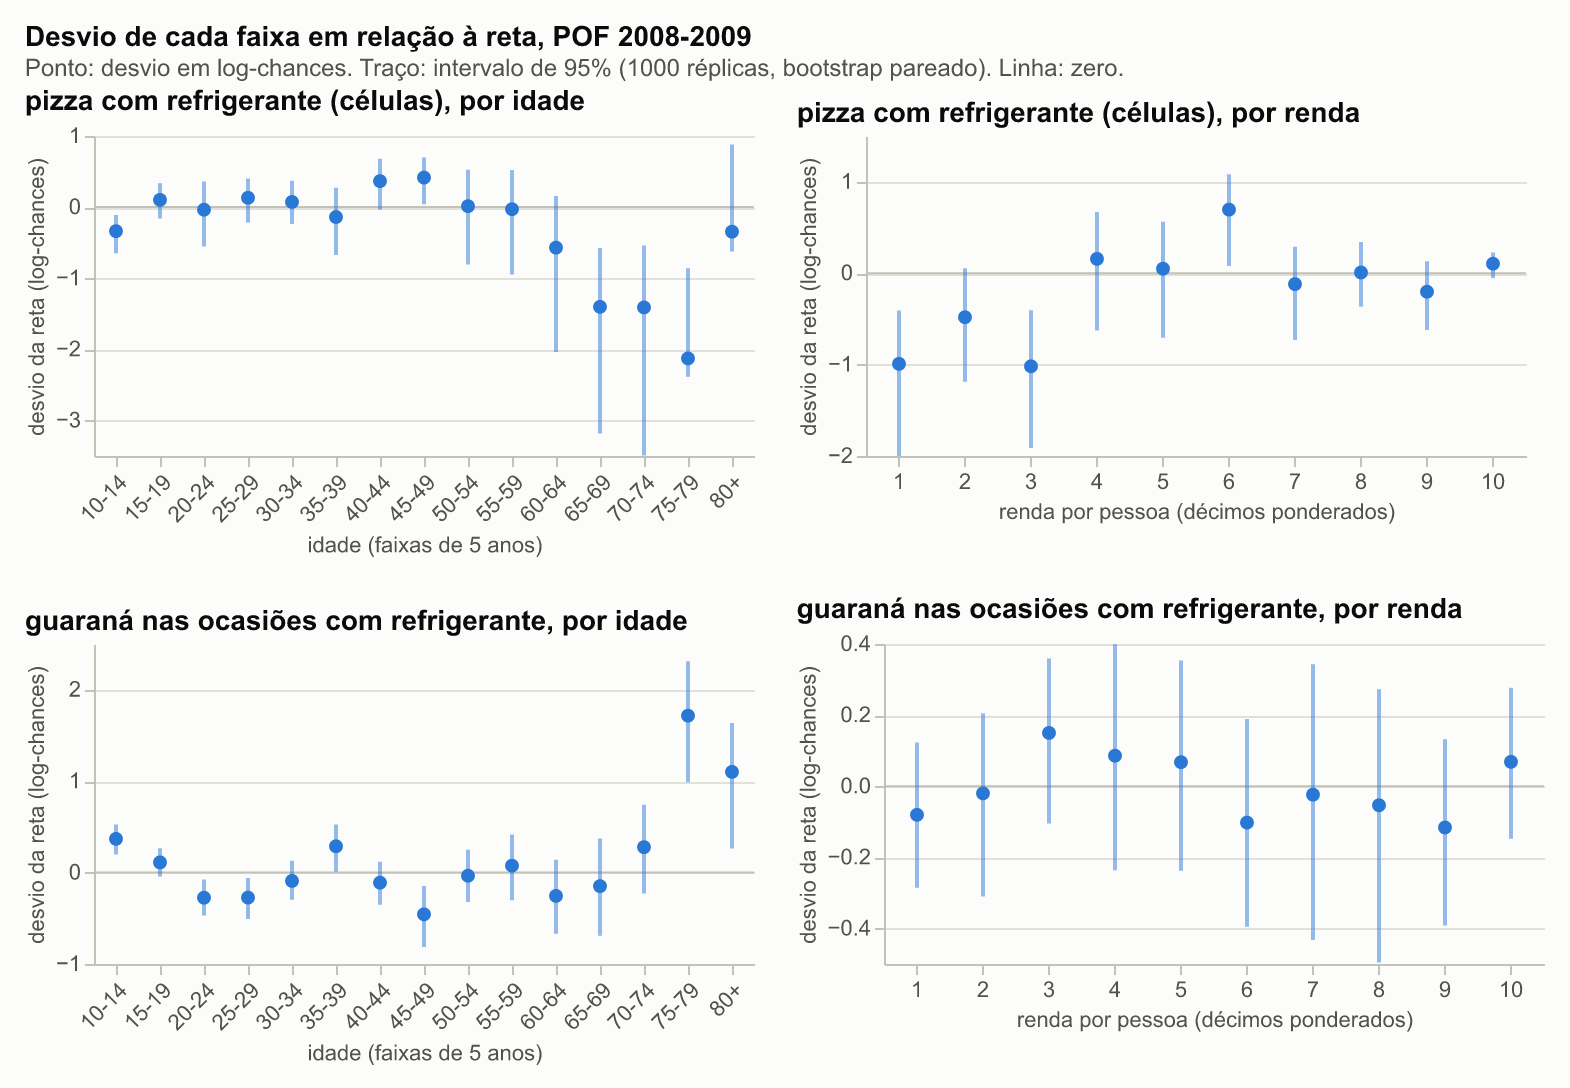

In [11]:
alt.vconcat(
    *[alt.hconcat(*[grafico_desvio(parte, eixo) for eixo in ESCALA]) for parte in PARTES]
).properties(
    title=alt.Title(
        "Desvio de cada faixa em relação à reta, POF 2008-2009",
        subtitle=f"Ponto: desvio em log-chances. Traço: intervalo de 95% ({B_DESTAQUE} réplicas, "
        "bootstrap pareado). Linha: zero.",
    )
)

In [12]:
cortes_decis = {
    parte: [
        round(float(c), 3)
        for c in quantis_ponderados(
            cfg["base"]["renda_pc_sm"], cfg["base"]["peso_final"], np.arange(1, 10) / 10
        )
    ]
    for parte, cfg in PARTES.items()
}
resumo_curvas = []
for parte in PARTES:
    for eixo, escala in ESCALA.items():
        t = curvas[parte][eixo]["tabela"]
        fora = t[t["exclui_zero"]]
        resumo_curvas.append(
            {
                "parte": parte,
                "eixo": eixo,
                "escala_da_reta": escala,
                "faixas": len(t),
                "faixas_com_desvio_que_exclui_zero": len(fora),
                "esperado_por_acaso": round(0.05 * len(t), 2),
                "onde": [f"{r.x} ({dec(r.desvio)})" for r in fora.itertuples()],
            }
        )
resumo_curvas = pd.DataFrame(resumo_curvas)
eda["curvas"] = {
    "metodo": (
        "logística ponderada de uma variável (idade linear ou log1p(renda_pc_sm)) ajustada no "
        "alvo; desvio por faixa = logit(taxa observada) - logit(taxa ajustada da faixa); "
        "intervalo percentil do bootstrap de setores dentro da UF, pareado (os mesmos "
        "multiplicadores na taxa e no reajuste); renda agrupada em centésimos ponderados"
    ),
    "b": B_DESTAQUE,
    "criterio_da_frase": (
        "a leitura diz que os dados sustentam desvio da reta quando o número de faixas cujo "
        "intervalo exclui zero passa do dobro do esperado por acaso (5% das faixas)"
    ),
    "cortes_decis_renda_sm": cortes_decis,
    "resumo": resumo_curvas.to_dict(orient="records"),
    "tabelas": {
        parte: {
            eixo: {
                "escala_da_reta": c["escala"],
                "inclinacao_por_desvio_padrao": round(c["inclinacao_por_desvio_padrao"], 4),
                "faixas": c["tabela"].drop(columns="pos").round(5).to_dict(orient="records"),
            }
            for eixo, c in por_eixo.items()
        }
        for parte, por_eixo in curvas.items()
    },
}
display(resumo_curvas)

,parte,eixo,escala_da_reta,faixas,faixas_com_desvio_que_exclui_zero,esperado_por_acaso,onde
0,ocasiao,idade (faixas de 5 anos),idade em anos,15,5,0.75,"[10-14 (-0,34), 45-49 (0,42), 65-69 (-1,40), 7..."
1,ocasiao,renda por pessoa (décimos ponderados),log1p(renda_pc_sm),10,3,0.50,"[1 (-0,99), 3 (-1,02), 6 (0,69)]"
2,preferencia,idade (faixas de 5 anos),idade em anos,15,7,0.75,"[10-14 (0,37), 20-24 (-0,28), 25-29 (-0,27), 3..."
3,preferencia,renda por pessoa (décimos ponderados),log1p(renda_pc_sm),10,0,0.50,[]


In [13]:
NOME_CURVA = {
    ("ocasiao", E_IDADE): "Ocasião por idade",
    ("ocasiao", E_RENDA): "Ocasião por renda",
    ("preferencia", E_IDADE): "Preferência por idade",
    ("preferencia", E_RENDA): "Preferência por renda",
}
frases = []
for r in resumo_curvas.itertuples():
    onde = f": {', '.join(r.onde)}" if r.onde else ""
    frases.append(
        f"{NOME_CURVA[(r.parte, r.eixo)]} (reta em {r.escala_da_reta}): "
        f"{r.faixas_com_desvio_que_exclui_zero} de {r.faixas} faixas com intervalo do desvio "
        f"que exclui zero{onde}"
    )
acima_do_acaso = resumo_curvas[
    resumo_curvas["faixas_com_desvio_que_exclui_zero"] > 2 * resumo_curvas["esperado_por_acaso"]
]
perto_do_acaso = resumo_curvas.drop(acima_do_acaso.index)
incompletas = [
    f"{NOME_CURVA[(parte, eixo)].lower()} {r.x} ({r.b_validas} de {B_DESTAQUE})"
    for parte in PARTES
    for eixo in ESCALA
    for r in curvas[parte][eixo]["tabela"].itertuples()
    if r.b_validas < B_DESTAQUE
]
eda["curvas"]["faixas_com_replicas_descartadas"] = incompletas
leitura(
    "; ".join(frases)
    + ". Por acaso, espera-se cerca de 5% das faixas fora (de "
    + f"{dec(resumo_curvas['esperado_por_acaso'].min())} a "
    + f"{dec(resumo_curvas['esperado_por_acaso'].max())} por curva). "
    + (
        "Os dados sustentam desvio da reta, com mais faixas fora do que o dobro do esperado por "
        "acaso, em: "
        + ", ".join(NOME_CURVA[(r.parte, r.eixo)].lower() for r in acima_do_acaso.itertuples())
        + ". "
        if len(acima_do_acaso)
        else "Em nenhuma curva o número de faixas fora passa do dobro do esperado por acaso. "
    )
    + (
        "Nas demais ("
        + ", ".join(NOME_CURVA[(r.parte, r.eixo)].lower() for r in perto_do_acaso.itertuples())
        + "), a EDA não distingue a curva da reta. "
        if len(perto_do_acaso)
        else ""
    )
    + (
        "Nas faixas com pouquíssimos positivos, as réplicas sem positivo não definem o desvio e "
        f"são descartadas ({'; '.join(incompletas)} réplicas válidas), o que deixa esses "
        "intervalos otimistas. "
        if incompletas
        else ""
    )
    + "A decisão de usar curvas (degrau C) é testada por H2 (C contra B) na validação, e não "
    "por esta EDA."
)

**Leitura.** Ocasião por idade (reta em idade em anos): 5 de 15 faixas com intervalo do desvio que exclui zero: 10-14 (-0,34), 45-49 (0,42), 65-69 (-1,40), 70-74 (-1,41), 75-79 (-2,13); Ocasião por renda (reta em log1p(renda_pc_sm)): 3 de 10 faixas com intervalo do desvio que exclui zero: 1 (-0,99), 3 (-1,02), 6 (0,69); Preferência por idade (reta em idade em anos): 7 de 15 faixas com intervalo do desvio que exclui zero: 10-14 (0,37), 20-24 (-0,28), 25-29 (-0,27), 35-39 (0,29), 45-49 (-0,46), 75-79 (1,72), 80+ (1,10); Preferência por renda (reta em log1p(renda_pc_sm)): 0 de 10 faixas com intervalo do desvio que exclui zero. Por acaso, espera-se cerca de 5% das faixas fora (de 0,50 a 0,75 por curva). Os dados sustentam desvio da reta, com mais faixas fora do que o dobro do esperado por acaso, em: ocasião por idade, ocasião por renda, preferência por idade. Nas demais (preferência por renda), a EDA não distingue a curva da reta. Nas faixas com pouquíssimos positivos, as réplicas sem positivo não definem o desvio e são descartadas (ocasião por idade 65-69 (980 de 1000); ocasião por idade 70-74 (980 de 1000); ocasião por idade 75-79 (675 de 1000); ocasião por idade 80+ (638 de 1000) réplicas válidas), o que deixa esses intervalos otimistas. A decisão de usar curvas (degrau C) é testada por H2 (C contra B) na validação, e não por esta EDA.

## 4. Interações candidatas

As interações pré-declaradas para o modelo (tarefa 6) são descritas aqui; **esta seção não
escolhe nem ordena interações pelo tamanho do desvio**. A lista vem do raciocínio do design,
não destes números.

Para cada par de variáveis, a tabela traz a taxa de cada combinação e o desvio, em
log-chances, entre a taxa da combinação e o que a soma dos efeitos marginais preveria:

desvio = logit(taxa do par) − logit(taxa de A) − logit(taxa de B) + logit(taxa geral).

Desvio zero quer dizer que, em log-chances, as duas variáveis se somam sem interagir. O
intervalo do desvio vem do mesmo bootstrap de setores. Combinações com menos de 10 positivos
aparecem sem cor.

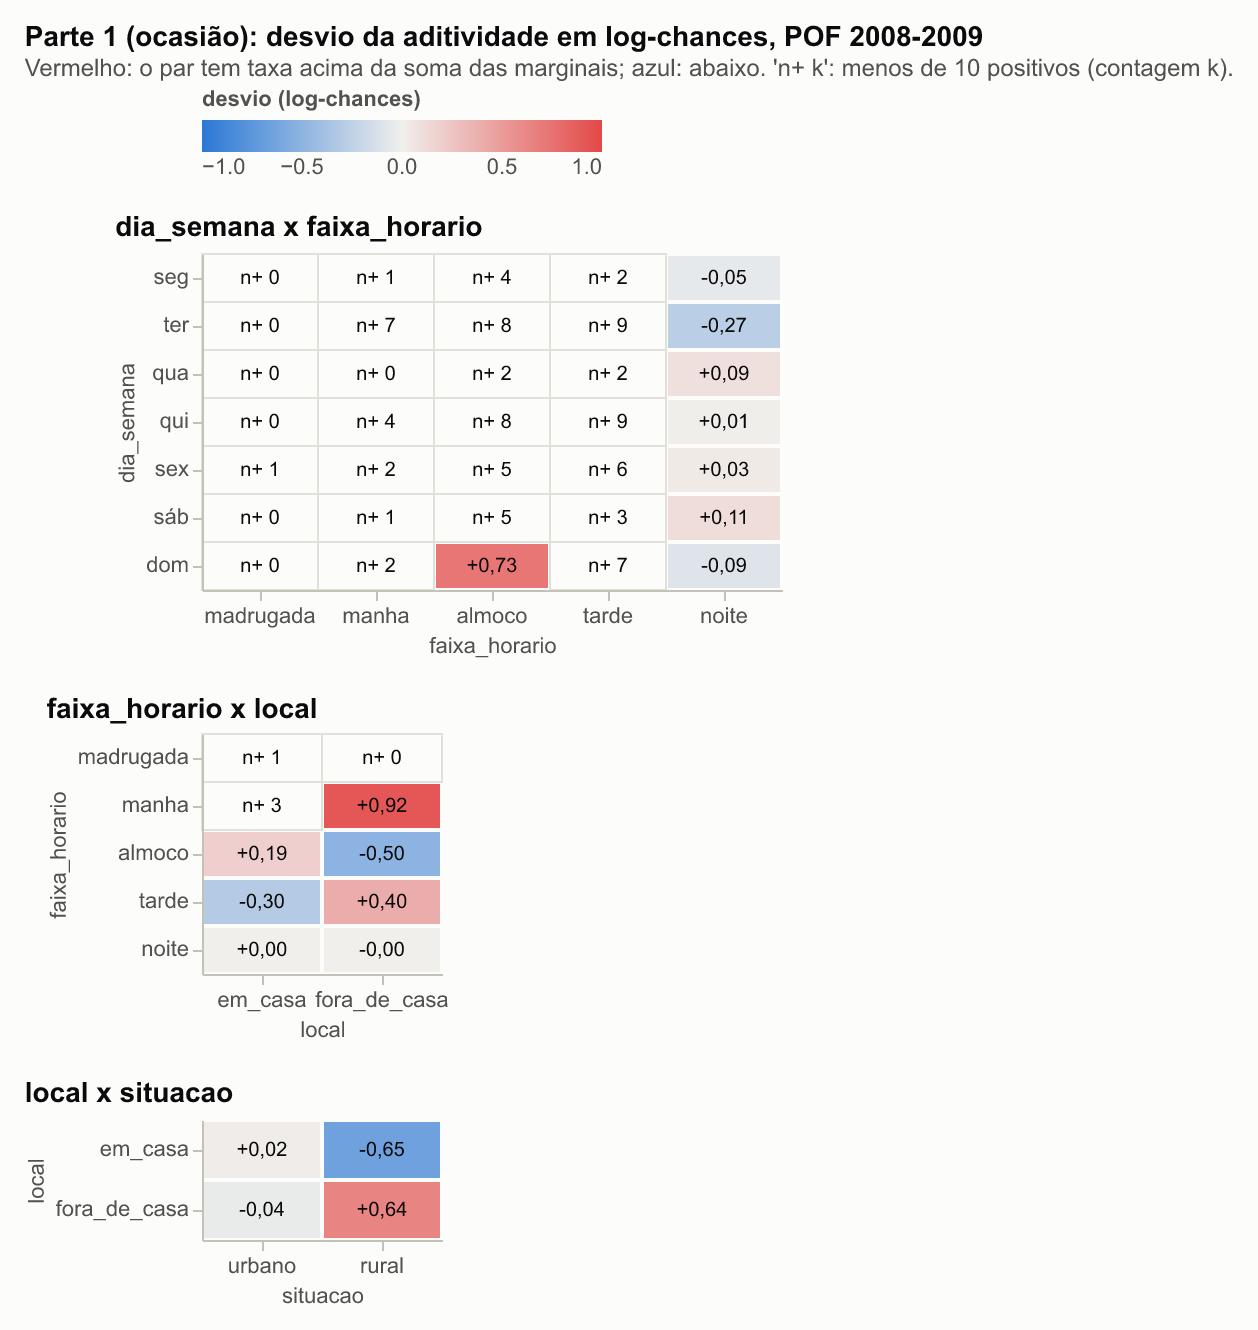

In [14]:
INTERACOES = {
    "ocasiao": [("dia_semana", "faixa_horario"), ("faixa_horario", "local"), ("local", "situacao")],
    "preferencia": [
        ("tem_pizza", "local"),
        ("tem_pizza", "regiao"),
        ("regiao", "local"),
        ("faixa_horario", "local"),
    ],
}
COLUNA_DA_VARIAVEL = {v: c for v, (c, _) in VARIAVEIS.items()} | {"tem_pizza": "tem_pizza"}
ORDEM_DA_VARIAVEL = {v: o for v, (_, o) in VARIAVEIS.items()} | {"tem_pizza": ["0", "1"]}
MIN_POS_INTERACAO = 10


def desvios_do_par(parte: str, a: str, b: str) -> pd.DataFrame:
    cfg = PARTES[parte]
    alvo = cfg["alvo"]
    ca, cb = COLUNA_DA_VARIAVEL[a], COLUNA_DA_VARIAVEL[b]
    base = cfg["base"].assign(**{ca: cfg["base"][ca].astype(str), cb: cfg["base"][cb].astype(str)})
    setores, uf = setores_e_uf(base)
    total = somas_por_setor(base, np.ones(len(base)), alvo, setores)
    marg = {
        (col, v): somas_por_setor(base, (base[col] == v).to_numpy(), alvo, setores)
        for col in (ca, cb)
        for v in base[col].unique()
    }
    linhas = []
    for (va, vb), g in base.groupby([ca, cb], observed=True):
        par = somas_por_setor(base, ((base[ca] == va) & (base[cb] == vb)).to_numpy(), alvo, setores)
        partes = [par, marg[(ca, va)], marg[(cb, vb)], total]

        def desvio(m: np.ndarray, partes: list = partes) -> float | None:
            taxas = []
            for w_s, wy_s in partes:
                den = float(m @ w_s)
                if den <= 0:
                    return None
                taxas.append(float(m @ wy_s) / den)
            if taxas[0] <= 0 or taxas[0] >= 1:
                return None
            lp, la, lb, lg = logit(np.array(taxas))
            return float(lp - la - lb + lg)

        estimativa = desvio(np.ones(len(setores)))
        intervalo = (
            intervalo_estatistica(desvio, setores, uf, b=B, semente=SEMENTE)
            if estimativa is not None
            else None
        )
        peso = g["peso_final"]
        linhas.append(
            {
                "par": f"{a} x {b}",
                "a": va,
                "b": vb,
                "n": len(g),
                "positivos": int(g[alvo].sum()),
                "taxa": float((peso * g[alvo]).sum() / peso.sum()),
                "desvio": estimativa,
                "desvio_ic_inf": intervalo.ic_inf if intervalo else None,
                "desvio_ic_sup": intervalo.ic_sup if intervalo else None,
            }
        )
    return pd.DataFrame(linhas)


interacoes = {
    parte: {f"{a} x {b}": desvios_do_par(parte, a, b) for a, b in pares}
    for parte, pares in INTERACOES.items()
}


def mapa_desvio(parte: str, a: str, b: str) -> alt.LayerChart:
    dados = interacoes[parte][f"{a} x {b}"].copy()
    dados["poucos"] = dados["positivos"] < MIN_POS_INTERACAO
    dados["rotulo"] = [
        f"n+ {p}" if pouco else f"{d:+.2f}".replace(".", ",")
        for p, d, pouco in zip(
            dados["positivos"], dados["desvio"].fillna(0), dados["poucos"], strict=True
        )
    ]
    x = alt.X("b:N", sort=ORDEM_DA_VARIAVEL[b], title=b, axis=alt.Axis(labelAngle=0))
    y = alt.Y("a:N", sort=ORDEM_DA_VARIAVEL[a], title=a)
    base = alt.Chart(dados)
    cor = alt.Color(
        "desvio:Q",
        title="desvio (log-chances)",
        scale=alt.Scale(
            domain=[-1, 0, 1], range=[AZUL, NEUTRO, VERMELHO], clamp=True, interpolate="rgb"
        ),
    )
    celulas_cor = (
        base.transform_filter("!datum.poucos")
        .mark_rect(stroke=SUPERFICIE, strokeWidth=2)
        .encode(x=x, y=y, color=cor)
    )
    celulas_vazias = (
        base.transform_filter("datum.poucos")
        .mark_rect(color=SUPERFICIE, stroke=GRADE, strokeWidth=1)
        .encode(x=x, y=y)
    )
    texto = base.mark_text(fontSize=10, color=TINTA).encode(x=x, y=y, text="rotulo:N")
    n_b = len(ORDEM_DA_VARIAVEL[b])
    return (celulas_cor + celulas_vazias + texto).properties(
        width=max(120, 58 * n_b), height=max(60, 24 * len(ORDEM_DA_VARIAVEL[a])), title=f"{a} x {b}"
    )


alt.vconcat(*[mapa_desvio("ocasiao", a, b) for a, b in INTERACOES["ocasiao"]]).resolve_scale(
    color="shared"
).properties(
    title=alt.Title(
        "Parte 1 (ocasião): desvio da aditividade em log-chances, POF 2008-2009",
        subtitle="Vermelho: o par tem taxa acima da soma das marginais; azul: abaixo. "
        "'n+ k': menos de 10 positivos (contagem k).",
    )
)

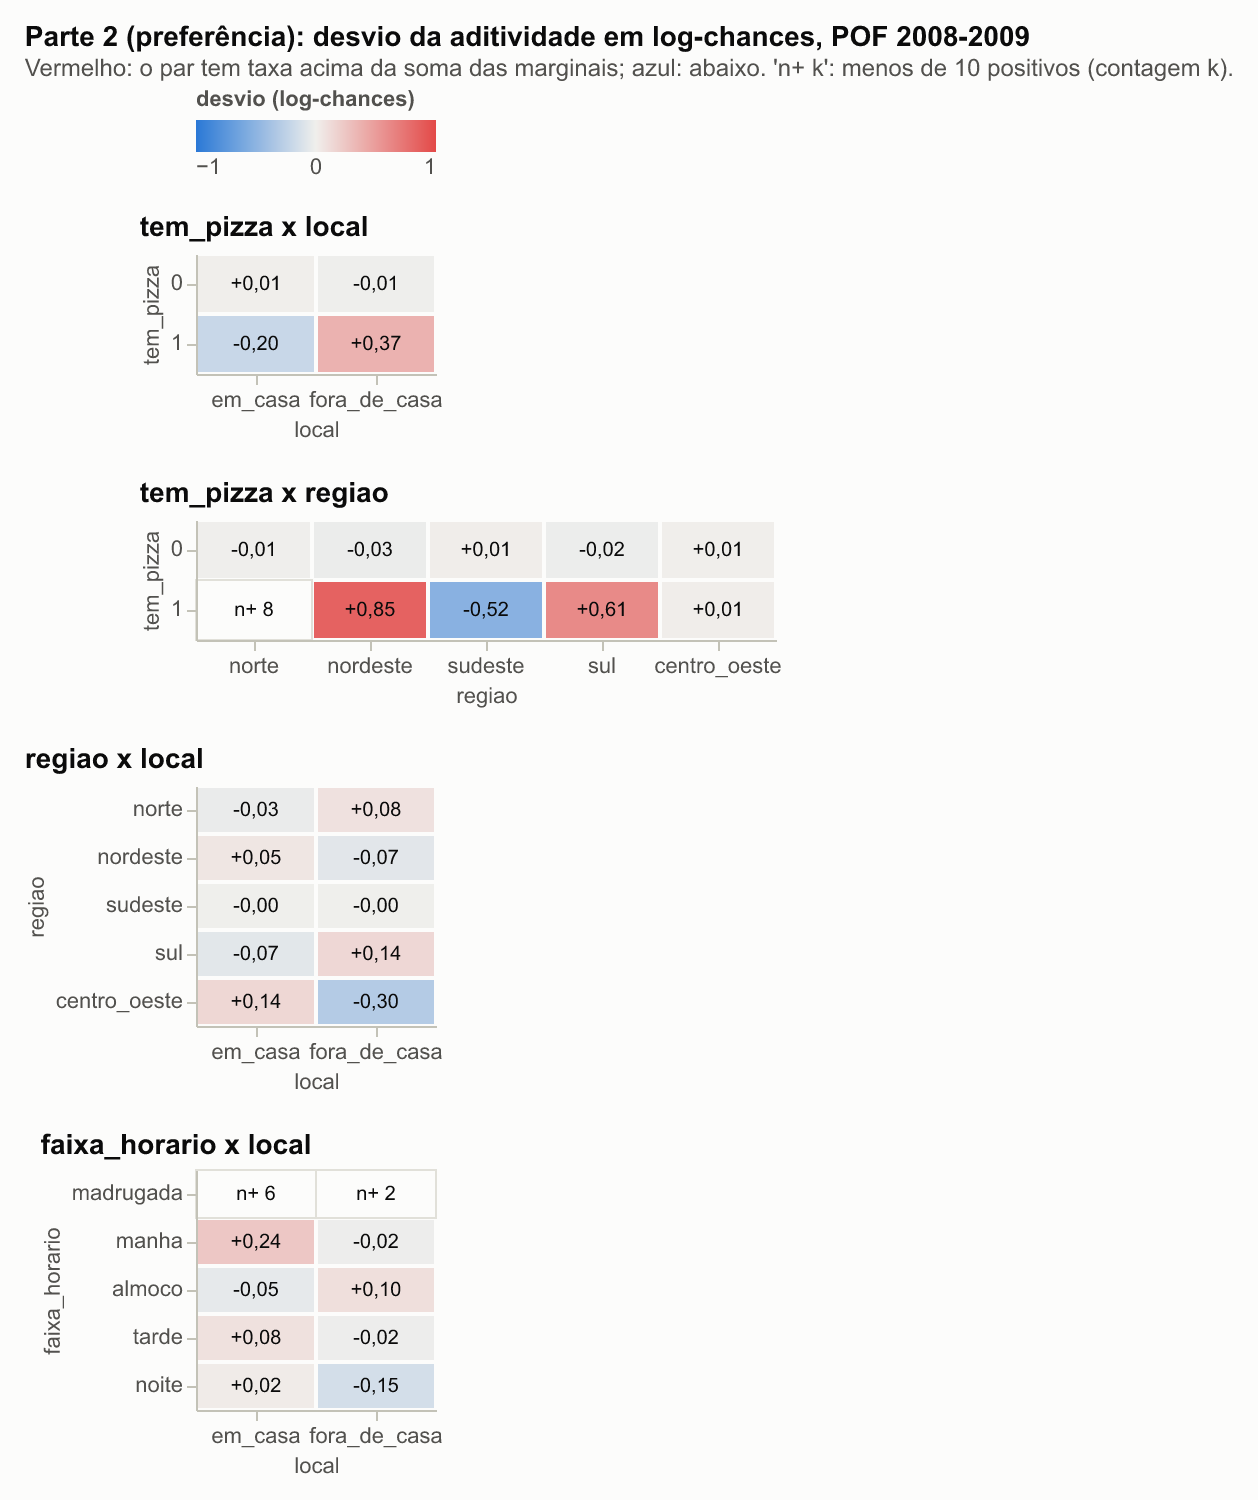

In [15]:
alt.vconcat(
    *[mapa_desvio("preferencia", a, b) for a, b in INTERACOES["preferencia"]]
).resolve_scale(color="shared").properties(
    title=alt.Title(
        "Parte 2 (preferência): desvio da aditividade em log-chances, POF 2008-2009",
        subtitle="Vermelho: o par tem taxa acima da soma das marginais; azul: abaixo. "
        "'n+ k': menos de 10 positivos (contagem k).",
    )
)

In [16]:
resumo_interacoes = []
for parte, pares in interacoes.items():
    for nome, t in pares.items():
        ok = t[t["positivos"] >= MIN_POS_INTERACAO].dropna(subset=["desvio"])
        fora_de_zero = ok[(ok["desvio_ic_inf"] > 0) | (ok["desvio_ic_sup"] < 0)]
        resumo_interacoes.append(
            {
                "parte": parte,
                "par": nome,
                "combinacoes": len(t),
                "graus_de_liberdade": (t["a"].nunique() - 1) * (t["b"].nunique() - 1),
                "com_10_ou_mais_positivos": len(ok),
                "intervalo_exclui_zero": len(fora_de_zero),
                "maior_desvio_absoluto": float(ok["desvio"].abs().max()) if len(ok) else None,
            }
        )
resumo_interacoes = pd.DataFrame(resumo_interacoes)
eda["interacoes"] = {
    "nota": "descrição; a lista de interações não é escolhida pelo tamanho do desvio",
    "resumo": resumo_interacoes.round(4).to_dict(orient="records"),
    "tabelas": {
        parte: {nome: t.round(5).to_dict(orient="records") for nome, t in pares.items()}
        for parte, pares in interacoes.items()
    },
}
display(resumo_interacoes.round(3))
n_intervalos = int(resumo_interacoes["com_10_ou_mais_positivos"].sum())
n_excluem = int(resumo_interacoes["intervalo_exclui_zero"].sum())
pares_2x2 = resumo_interacoes.loc[resumo_interacoes["graus_de_liberdade"] == 1, "par"].tolist()
eda["interacoes"]["intervalos_calculados"] = n_intervalos
eda["interacoes"]["intervalos_que_excluem_zero"] = n_excluem
eda["interacoes"]["esperado_por_acaso"] = round(0.05 * n_intervalos, 2)
leitura(
    "Combinações com 10 ou mais positivos cujo intervalo do desvio exclui zero, por par: "
    + "; ".join(
        f"{r.par} ({r.parte}): {r.intervalo_exclui_zero} de {r.com_10_ou_mais_positivos}"
        for r in resumo_interacoes.itertuples()
    )
    + ". É uma descrição do quanto cada par se afasta da soma das marginais; ela não escolhe nem "
    "ordena as interações do modelo. Duas ressalvas: "
    + (
        f"{' e '.join(pares_2x2)} {'é uma tabela' if len(pares_2x2) == 1 else 'são tabelas'} 2x2 "
        "com 1 grau de liberdade: os quatro desvios vêm de um único parâmetro de interação e "
        "não são quatro evidências; "
        if pares_2x2
        else ""
    )
    + f"e, com {n_intervalos} intervalos de 95%, cerca de {dec(0.05 * n_intervalos, 1)} "
    f"excluiriam zero só por acaso ({n_excluem} excluem)."
)

,parte,par,combinacoes,graus_de_liberdade,com_10_ou_mais_positivos,intervalo_exclui_zero,maior_desvio_absoluto
0,ocasiao,dia_semana x faixa_horario,35,24,8,3,0.729
1,ocasiao,faixa_horario x local,10,4,7,1,0.918
2,ocasiao,local x situacao,4,1,4,4,0.654
3,preferencia,tem_pizza x local,4,1,4,0,0.368
4,preferencia,tem_pizza x regiao,10,4,9,4,0.850
5,preferencia,regiao x local,10,4,10,2,0.304
6,preferencia,faixa_horario x local,10,4,8,2,0.239


**Leitura.** Combinações com 10 ou mais positivos cujo intervalo do desvio exclui zero, por par: dia_semana x faixa_horario (ocasiao): 3 de 8; faixa_horario x local (ocasiao): 1 de 7; local x situacao (ocasiao): 4 de 4; tem_pizza x local (preferencia): 0 de 4; tem_pizza x regiao (preferencia): 4 de 9; regiao x local (preferencia): 2 de 10; faixa_horario x local (preferencia): 2 de 8. É uma descrição do quanto cada par se afasta da soma das marginais; ela não escolhe nem ordena as interações do modelo. Duas ressalvas: local x situacao e tem_pizza x local são tabelas 2x2 com 1 grau de liberdade: os quatro desvios vêm de um único parâmetro de interação e não são quatro evidências; e, com 50 intervalos de 95%, cerca de 2,5 excluiriam zero só por acaso (16 excluem).

## 5. Pizza e preferência

Participação ponderada do guaraná nas ocasiões com refrigerante, com e sem pizza na mesma
ocasião, e a mesma conta para a cola como referência. A seção 4.3 do design registra uma
observação anterior sobre essa diferença; aqui ela é refeita só com 2008-2009.

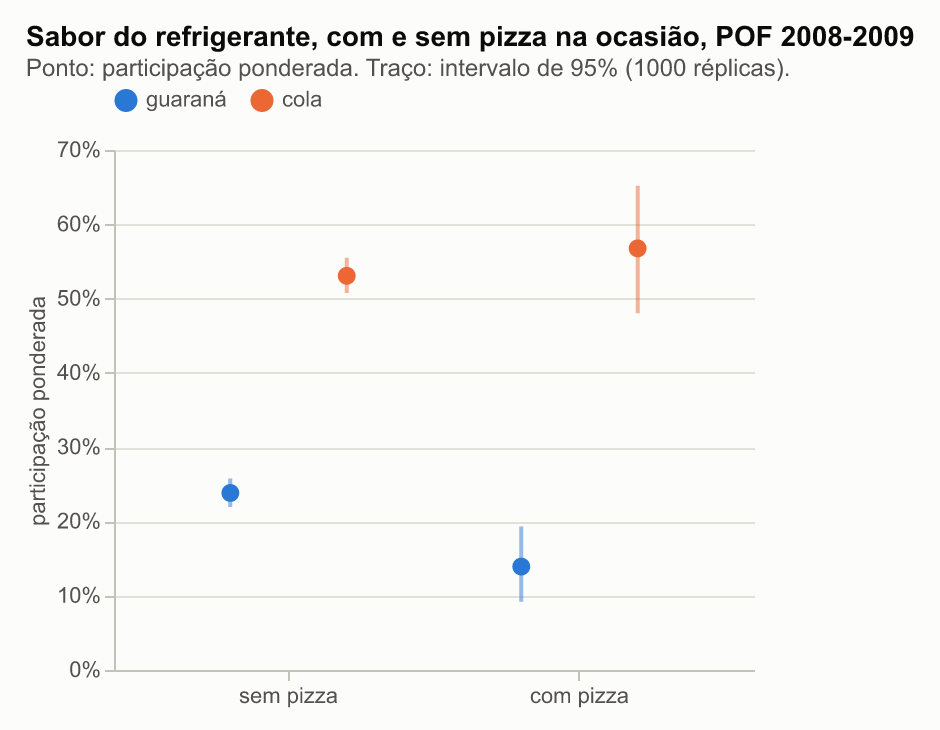

In [17]:
ocas_refri = ocasioes[ocasioes["tem_refri"]].assign(
    tem_pizza=lambda d: d["tem_pizza"].astype(int),
    y_guarana=lambda d: d["tem_guarana"].astype(int),
    y_cola=lambda d: d["tem_cola"].astype(int),
)
assert len(ocas_refri) == len(refri)
sabores = pd.concat(
    [
        taxas(ocas_refri, alvo, ["tem_pizza"], b=B_DESTAQUE).assign(sabor=sabor)
        for alvo, sabor in [("y_guarana", "guaraná"), ("y_cola", "cola")]
    ],
    ignore_index=True,
)
sabores["ocasião"] = sabores["tem_pizza"].map({0: "sem pizza", 1: "com pizza"})

setores_r, uf_r = setores_e_uf(ocas_refri)


def diferenca(alvo: str) -> Any:
    com = somas_por_setor(ocas_refri, (ocas_refri["tem_pizza"] == 1).to_numpy(), alvo, setores_r)
    sem = somas_por_setor(ocas_refri, (ocas_refri["tem_pizza"] == 0).to_numpy(), alvo, setores_r)

    def dif(m: np.ndarray) -> float | None:
        d_com, d_sem = float(m @ com[0]), float(m @ sem[0])
        if d_com <= 0 or d_sem <= 0:
            return None
        return float(m @ com[1]) / d_com - float(m @ sem[1]) / d_sem

    return intervalo_estatistica(dif, setores_r, uf_r, b=B_DESTAQUE, semente=SEMENTE)


dif_guarana, dif_cola = diferenca("y_guarana"), diferenca("y_cola")

cores_sabor = alt.Scale(domain=["guaraná", "cola"], range=[AZUL, LARANJA])
x_sabor = alt.X(
    "ocasião:N", sort=["sem pizza", "com pizza"], title=None, axis=alt.Axis(labelAngle=0)
)
xo = alt.XOffset("sabor:N", sort=["guaraná", "cola"])
base_sab = alt.Chart(sabores)
(
    base_sab.mark_rule(strokeWidth=2, opacity=0.5).encode(
        x=x_sabor,
        xOffset=xo,
        y=alt.Y("ic_inf:Q", title="participação ponderada", axis=alt.Axis(format=".0%")),
        y2="ic_sup:Q",
        color=alt.Color("sabor:N", scale=cores_sabor, title=None),
    )
    + base_sab.mark_point(filled=True, size=80, opacity=1).encode(
        x=x_sabor, xOffset=xo, y="taxa:Q", color=alt.Color("sabor:N", scale=cores_sabor, title=None)
    )
).properties(
    width=320,
    height=260,
    title=alt.Title(
        "Sabor do refrigerante, com e sem pizza na ocasião, POF 2008-2009",
        subtitle=f"Ponto: participação ponderada. Traço: intervalo de 95% ({B_DESTAQUE} réplicas).",
    ),
)

In [18]:
g = sabores[sabores["sabor"] == "guaraná"].set_index("tem_pizza")
c = sabores[sabores["sabor"] == "cola"].set_index("tem_pizza")
eda["pizza_e_preferencia"] = {
    "b": B_DESTAQUE,
    "guarana_sem_pizza": {k: round(float(g.loc[0, k]), 5) for k in ["taxa", "ic_inf", "ic_sup"]}
    | {"n": int(g.loc[0, "n"]), "positivos": int(g.loc[0, "positivos"])},
    "guarana_com_pizza": {k: round(float(g.loc[1, k]), 5) for k in ["taxa", "ic_inf", "ic_sup"]}
    | {"n": int(g.loc[1, "n"]), "positivos": int(g.loc[1, "positivos"])},
    "diferenca_guarana_com_menos_sem": {
        "estimativa": round(dif_guarana.estimativa, 5),
        "ic_inf": round(dif_guarana.ic_inf, 5),
        "ic_sup": round(dif_guarana.ic_sup, 5),
    },
    "cola_sem_pizza": round(float(c.loc[0, "taxa"]), 5),
    "cola_com_pizza": round(float(c.loc[1, "taxa"]), 5),
    "diferenca_cola_com_menos_sem": {
        "estimativa": round(dif_cola.estimativa, 5),
        "ic_inf": round(dif_cola.ic_inf, 5),
        "ic_sup": round(dif_cola.ic_sup, 5),
    },
}


def pontos_pct(x: float) -> str:
    return f"{100 * x:+.1f} p.p.".replace(".", ",", 1)


exclui = dif_guarana.ic_inf > 0 or dif_guarana.ic_sup < 0
leitura(
    f"O guaraná responde por {ic(g.loc[0])} das ocasiões com refrigerante sem pizza e por "
    f"{ic(g.loc[1])} das com pizza ({inteiro(g.loc[1, 'n'])} ocasiões com pizza, "
    f"{int(g.loc[1, 'positivos'])} com guaraná, em contagem simples). A diferença com menos sem "
    f"pizza é {pontos_pct(dif_guarana.estimativa)} (IC de 95%: {pontos_pct(dif_guarana.ic_inf)} a "
    f"{pontos_pct(dif_guarana.ic_sup)}), "
    + ("um intervalo que exclui zero" if exclui else "um intervalo que inclui zero")
    + f". A cola vai de {pct(c.loc[0, 'taxa'])} sem pizza para {pct(c.loc[1, 'taxa'])} com pizza "
    f"(diferença de {pontos_pct(dif_cola.estimativa)}, IC de {pontos_pct(dif_cola.ic_inf)} a "
    f"{pontos_pct(dif_cola.ic_sup)})."
)

**Leitura.** O guaraná responde por 23,8% (IC de 95%: 21,9% a 25,8%) das ocasiões com refrigerante sem pizza e por 13,9% (IC de 95%: 9,2% a 19,3%) das com pizza (655 ocasiões com pizza, 101 com guaraná, em contagem simples). A diferença com menos sem pizza é -9,9 p.p. (IC de 95%: -14,9 p.p. a -4,4 p.p.), um intervalo que exclui zero. A cola vai de 53,1% sem pizza para 56,8% com pizza (diferença de +3,7 p.p., IC de -4,9 p.p. a +12,2 p.p.).

## 6. Sazonalidade

Taxa ponderada de dias com pizza e refrigerante no mesmo horário (`tem_pizza_refri`, por
pessoa x dia) por trimestre do ano. A data de calendário de cada dia é reconstruída por
`edicao_2008()` de `scripts/investigacao_datas.py` (seção 26 do registro de decisões). É só
descrição: nenhuma variável de época entra no modelo.

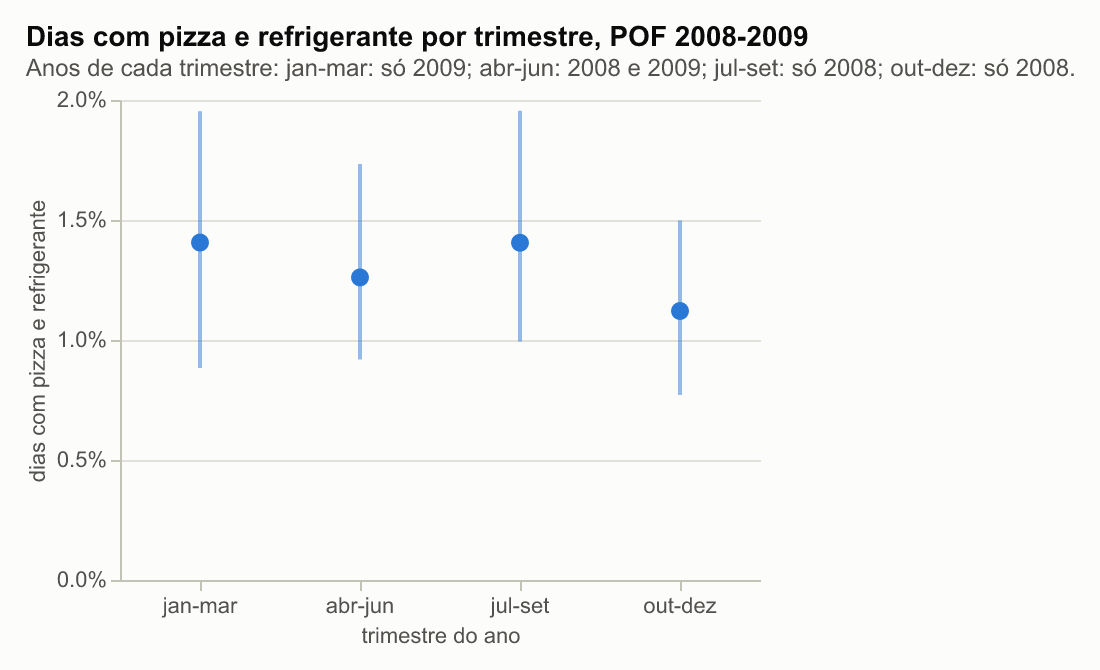

In [19]:
_spec = importlib.util.spec_from_file_location(
    "investigacao_datas", RAIZ / "scripts" / "investigacao_datas.py"
)
assert _spec is not None and _spec.loader is not None
investigacao_datas = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(investigacao_datas)
_, com_data = investigacao_datas.edicao_2008()

TRIMESTRES = {1: "jan-mar", 2: "abr-jun", 3: "jul-set", 4: "out-dez"}
com_data = com_data.assign(
    trimestre=com_data["data"].dt.quarter.map(TRIMESTRES),
    y=com_data["tem_pizza_refri"].astype(int),
)
sazonal = taxas(com_data, "y", ["trimestre"])
sazonal["ordem"] = sazonal["trimestre"].map({v: k for k, v in TRIMESTRES.items()})
sazonal = sazonal.sort_values("ordem")
meses_por_trimestre = com_data.groupby("trimestre")["data"].agg(
    lambda s: sorted({str(p) for p in s.dt.to_period("M")})
)
anos_por_trimestre = {
    t: sorted({m[:4] for m in meses_por_trimestre[t]}) for t in TRIMESTRES.values()
}


def anos_do_trimestre(t: str) -> str:
    anos = anos_por_trimestre[t]
    return f"só {anos[0]}" if len(anos) == 1 else " e ".join(anos)


descricao_anos = "; ".join(f"{t}: {anos_do_trimestre(t)}" for t in TRIMESTRES.values())
estacao_e_ano_confundidos = len({tuple(a) for a in anos_por_trimestre.values()}) > 1

x_tri = alt.X(
    "trimestre:N",
    sort=list(TRIMESTRES.values()),
    title="trimestre do ano",
    axis=alt.Axis(labelAngle=0),
)
(
    alt.Chart(sazonal)
    .mark_rule(color=AZUL, strokeWidth=2, opacity=0.5)
    .encode(
        x=x_tri,
        y=alt.Y("ic_inf:Q", title="dias com pizza e refrigerante", axis=alt.Axis(format=".1%")),
        y2="ic_sup:Q",
    )
    + alt.Chart(sazonal)
    .mark_point(color=AZUL, filled=True, size=80, opacity=1)
    .encode(x=x_tri, y="taxa:Q")
).properties(
    width=320,
    height=240,
    title=alt.Title(
        "Dias com pizza e refrigerante por trimestre, POF 2008-2009",
        subtitle=f"Anos de cada trimestre: {descricao_anos}.",
    ),
)

In [20]:
alto, baixo = sazonal.loc[sazonal["taxa"].idxmax()], sazonal.loc[sazonal["taxa"].idxmin()]
separados = bool(alto["ic_inf"] > baixo["ic_sup"])
eda["sazonalidade"] = {
    "dias_pessoa_com_data": len(com_data),
    "dias_pessoa_total": len(pessoa_dia),
    "por_trimestre": sazonal.drop(columns="ordem").round(5).to_dict(orient="records"),
    "meses_por_trimestre": {k: v for k, v in meses_por_trimestre.items()},
    "anos_por_trimestre": anos_por_trimestre,
    "estacao_e_ano_confundidos": estacao_e_ano_confundidos,
    "intervalos_do_maior_e_do_menor_separados": separados,
}
leitura(
    f"A data foi reconstruída para {inteiro(len(com_data))} dos {inteiro(len(pessoa_dia))} "
    f"dias-pessoa. A maior taxa é em {alto['trimestre']}, {ic(alto)}, e a menor em "
    f"{baixo['trimestre']}, {ic(baixo)}; "
    + ("os dois intervalos não se cruzam." if separados else "os dois intervalos se cruzam.")
    + (
        f" Estação e ano se confundem: {descricao_anos}. Uma diferença entre trimestres não "
        "separa época do ano de mudança entre 2008 e 2009."
        if estacao_e_ano_confundidos
        else ""
    )
    + " Nada disso vira variável: o registro de consumo da edição de teste não tem data de calendário."
)

**Leitura.** A data foi reconstruída para 66.885 dos 66.903 dias-pessoa. A maior taxa é em jan-mar, 1,4% (IC de 95%: 0,9% a 2,0%), e a menor em out-dez, 1,1% (IC de 95%: 0,8% a 1,5%); os dois intervalos se cruzam. Estação e ano se confundem: jan-mar: só 2009; abr-jun: 2008 e 2009; jul-set: só 2008; out-dez: só 2008. Uma diferença entre trimestres não separa época do ano de mudança entre 2008 e 2009. Nada disso vira variável: o registro de consumo da edição de teste não tem data de calendário.

## 7. O que o TAPI diz

O TAPI afirma que a ocasião pizza com refrigerante "se concentra de sexta a domingo, à noite e
dentro de casa", e que os dados da empresa mostram maior consumo de pizza na classe A e maior
associação da marca de guaraná com a ocasião nesse segmento. O item 23 do registro de decisões
anota o contraste: a POF mede o sabor, em todas as ocasiões com refrigerante, e não a marca na
ocasião de pizza. Aqui as duas afirmações são olhadas em 2008-2009.

Só taxas são comparadas entre dias. A fatia das ocasiões que cai em cada dia não é calculada,
porque a composição de dias da amostra de 2008-2009 segue o desenho de coleta (excesso de
terças e quintas) e o peso amostral não a corrige. "Em casa" é a fonte do alimento nesta
edição (ver seção 2).

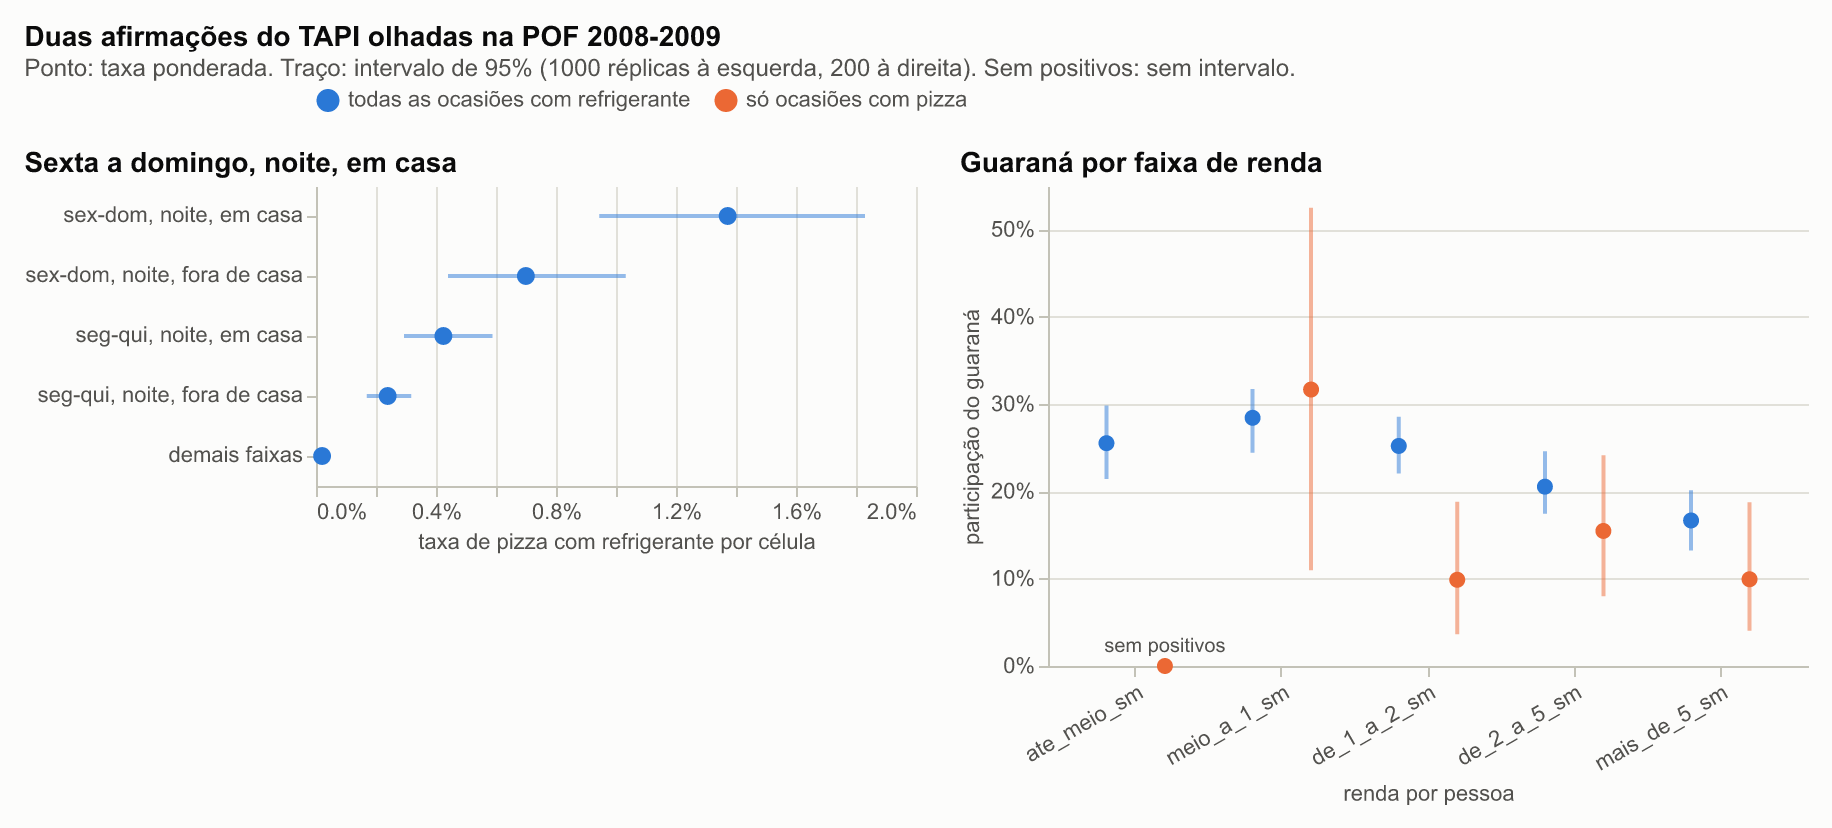

In [21]:
fds = celulas["dia_semana"].isin([5, 6, 7])
noite = celulas["faixa_horario"] == "noite"
em_casa = celulas["local"] == "em_casa"
celulas["contexto_tapi"] = np.select(
    [
        fds & noite & em_casa,
        fds & noite & ~em_casa,
        ~fds & noite & em_casa,
        ~fds & noite & ~em_casa,
    ],
    [
        "sex-dom, noite, em casa",
        "sex-dom, noite, fora de casa",
        "seg-qui, noite, em casa",
        "seg-qui, noite, fora de casa",
    ],
    default="demais faixas",
)
tapi = taxas(celulas, "y_pizza_refri", ["contexto_tapi"], b=B_DESTAQUE).set_index("contexto_tapi")

setores_c, uf_c = setores_e_uf(celulas)


def razao_de_taxas(mascara_a: np.ndarray, mascara_b: np.ndarray) -> Any:
    sa = somas_por_setor(celulas, mascara_a, "y_pizza_refri", setores_c)
    sb = somas_por_setor(celulas, mascara_b, "y_pizza_refri", setores_c)

    def razao(m: np.ndarray) -> float | None:
        da, db, nb = float(m @ sa[0]), float(m @ sb[0]), float(m @ sb[1])
        if da <= 0 or db <= 0 or nb <= 0:
            return None
        return (float(m @ sa[1]) / da) / (nb / db)

    return intervalo_estatistica(razao, setores_c, uf_c, b=B_DESTAQUE, semente=SEMENTE)


razao_fds = razao_de_taxas((fds & noite & em_casa).to_numpy(), (~fds & noite & em_casa).to_numpy())
razao_casa = razao_de_taxas((fds & noite & em_casa).to_numpy(), (fds & noite & ~em_casa).to_numpy())

renda_guarana = taxas(refri, "y_guarana", ["faixa_renda"]).assign(
    conjunto="todas as ocasiões com refrigerante"
)
renda_guarana_pizza = taxas(refri[refri["tem_pizza"] == 1], "y_guarana", ["faixa_renda"]).assign(
    conjunto="só ocasiões com pizza"
)
renda_ocasiao = (
    taxas_por_variavel["ocasiao"].query("variavel == 'renda_pc_sm'").set_index("categoria")
)
renda_tab = pd.concat([renda_guarana, renda_guarana_pizza], ignore_index=True)

ordem_tapi = [
    "sex-dom, noite, em casa",
    "sex-dom, noite, fora de casa",
    "seg-qui, noite, em casa",
    "seg-qui, noite, fora de casa",
    "demais faixas",
]
dados_tapi = tapi.reset_index()
y_tapi = alt.Y("contexto_tapi:N", sort=ordem_tapi, title=None)
grafico_tapi = (
    alt.Chart(dados_tapi)
    .mark_rule(color=AZUL, strokeWidth=2, opacity=0.5)
    .encode(
        y=y_tapi,
        x=alt.X(
            "ic_inf:Q",
            title="taxa de pizza com refrigerante por célula",
            axis=alt.Axis(format=".1%"),
        ),
        x2="ic_sup:Q",
    )
    + alt.Chart(dados_tapi)
    .mark_point(color=AZUL, filled=True, size=80, opacity=1)
    .encode(y=y_tapi, x="taxa:Q")
).properties(width=300, height=150, title="Sexta a domingo, noite, em casa")

cores_conj = alt.Scale(
    domain=["todas as ocasiões com refrigerante", "só ocasiões com pizza"], range=[AZUL, LARANJA]
)
x_renda = alt.X(
    "faixa_renda:N", sort=ORDEM_RENDA, title="renda por pessoa", axis=alt.Axis(labelAngle=-30)
)
xo_r = alt.XOffset("conjunto:N", sort=list(cores_conj.domain))
grafico_renda = (
    alt.Chart(renda_tab)
    .mark_rule(strokeWidth=2, opacity=0.5)
    .encode(
        x=x_renda,
        xOffset=xo_r,
        y=alt.Y("ic_inf:Q", title="participação do guaraná", axis=alt.Axis(format=".0%")),
        y2="ic_sup:Q",
        color=alt.Color("conjunto:N", scale=cores_conj, title=None),
    )
    + alt.Chart(renda_tab)
    .mark_point(filled=True, size=64, opacity=1)
    .encode(
        x=x_renda,
        xOffset=xo_r,
        y="taxa:Q",
        color=alt.Color("conjunto:N", scale=cores_conj, title=None),
    )
    + alt.Chart(renda_tab[renda_tab["sem_positivos"]])
    .mark_text(color=TINTA_2, fontSize=10, dy=-10)
    .encode(x=x_renda, xOffset=xo_r, y="taxa:Q", text=alt.value("sem positivos"))
).properties(width=380, height=240, title="Guaraná por faixa de renda")

alt.hconcat(grafico_tapi, grafico_renda).properties(
    title=alt.Title(
        "Duas afirmações do TAPI olhadas na POF 2008-2009",
        subtitle=f"Ponto: taxa ponderada. Traço: intervalo de 95% ({B_DESTAQUE} réplicas à "
        f"esquerda, {B} à direita). Sem positivos: sem intervalo.",
    )
)

In [22]:
r_g = renda_guarana.set_index("faixa_renda")
r_gp = renda_guarana_pizza.set_index("faixa_renda")
COLUNAS_TAXA = ["n", "positivos", "taxa", "ic_inf", "ic_sup", "sem_positivos", "b"]
eda["tapi"] = {
    "pizza_refri_por_contexto": tapi[COLUNAS_TAXA].round(5).to_dict(orient="index"),
    "razao_sex_dom_sobre_seg_qui_noite_em_casa": {
        "estimativa": round(razao_fds.estimativa, 4),
        "ic_inf": round(razao_fds.ic_inf, 4),
        "ic_sup": round(razao_fds.ic_sup, 4),
        "b": razao_fds.b,
    },
    "razao_em_casa_sobre_fora_sex_dom_noite": {
        "estimativa": round(razao_casa.estimativa, 4),
        "ic_inf": round(razao_casa.ic_inf, 4),
        "ic_sup": round(razao_casa.ic_sup, 4),
        "b": razao_casa.b,
    },
    "pizza_refri_por_renda": renda_ocasiao[COLUNAS_TAXA].round(5).to_dict(orient="index"),
    "guarana_por_renda_todas": r_g[COLUNAS_TAXA].round(5).to_dict(orient="index"),
    "guarana_por_renda_com_pizza": r_gp[COLUNAS_TAXA].round(5).to_dict(orient="index"),
}
s, q = tapi.loc["sex-dom, noite, em casa"], tapi.loc["seg-qui, noite, em casa"]
sf, dem = tapi.loc["sex-dom, noite, fora de casa"], tapi.loc["demais faixas"]


def ic_razao(r: Any) -> str:
    return f"{dec(r.estimativa, 1)} (IC de 95%: {dec(r.ic_inf, 1)} a {dec(r.ic_sup, 1)})"


topo_renda, base_renda = ORDEM_RENDA[-1], ORDEM_RENDA[0]
leitura(
    f"Sexta a domingo à noite em casa, a taxa por célula é {ic(s)}, contra {ic(q)} de segunda a "
    f"quinta no mesmo horário e local, uma razão de {ic_razao(razao_fds)}. Sexta a domingo à "
    f"noite fora de casa, a taxa é {ic(sf)}; em casa sobre fora, nesses dias e nessa faixa, a "
    f"razão é {ic_razao(razao_casa)}. Fora da noite, a taxa é {pct(dem['taxa'], 2)}. "
    f"A ocasião por célula vai de {pct(renda_ocasiao.loc[base_renda, 'taxa'], 2)} em {base_renda} "
    f"a {pct(renda_ocasiao.loc[topo_renda, 'taxa'], 2)} em {topo_renda}. Já o guaraná nas "
    f"ocasiões com refrigerante vai de {ic(r_g.loc[base_renda])} em {base_renda} a "
    f"{ic(r_g.loc[topo_renda])} em {topo_renda}; só nas ocasiões com pizza, com "
    f"{int(r_gp['positivos'].sum())} positivos ao todo, os intervalos são largos (de "
    f"{pct(r_gp['ic_inf'].min())} a {pct(r_gp['ic_sup'].max())})"
    + (
        f", e {', '.join(r_gp.index[r_gp['sem_positivos']])} não tem nenhum positivo "
        f"({', '.join(str(int(n)) for n in r_gp.loc[r_gp['sem_positivos'], 'n'])} ocasiões)"
        if r_gp["sem_positivos"].any()
        else ""
    )
    + ". A POF descreve o sabor, não a "
    "marca, e a classe A não tem correspondência direta com as faixas de renda por pessoa."
)

**Leitura.** Sexta a domingo à noite em casa, a taxa por célula é 1,4% (IC de 95%: 0,9% a 1,8%), contra 0,4% (IC de 95%: 0,3% a 0,6%) de segunda a quinta no mesmo horário e local, uma razão de 3,2 (IC de 95%: 2,1 a 5,1). Sexta a domingo à noite fora de casa, a taxa é 0,7% (IC de 95%: 0,4% a 1,0%); em casa sobre fora, nesses dias e nessa faixa, a razão é 2,0 (IC de 95%: 1,2 a 3,4). Fora da noite, a taxa é 0,02%. A ocasião por célula vai de 0,03% em ate_meio_sm a 0,37% em mais_de_5_sm. Já o guaraná nas ocasiões com refrigerante vai de 25,5% (IC de 95%: 21,4% a 29,9%) em ate_meio_sm a 16,7% (IC de 95%: 13,2% a 20,1%) em mais_de_5_sm; só nas ocasiões com pizza, com 101 positivos ao todo, os intervalos são largos (de 3,6% a 52,5%), e ate_meio_sm não tem nenhum positivo (44 ocasiões). A POF descreve o sabor, não a marca, e a classe A não tem correspondência direta com as faixas de renda por pessoa.

## 8. Esparsidade do degrau A

Positivos (contagem simples) em cada combinação das dimensões da tabela de taxas do degrau A:
`DIMENSOES_PARTE_1` (dia da semana x faixa de horário x local) para a ocasião e
`DIMENSOES_PARTE_2` (região x local) para a preferência. Combinações com poucos positivos são
puxadas para a taxa geral pela suavização da tabela.

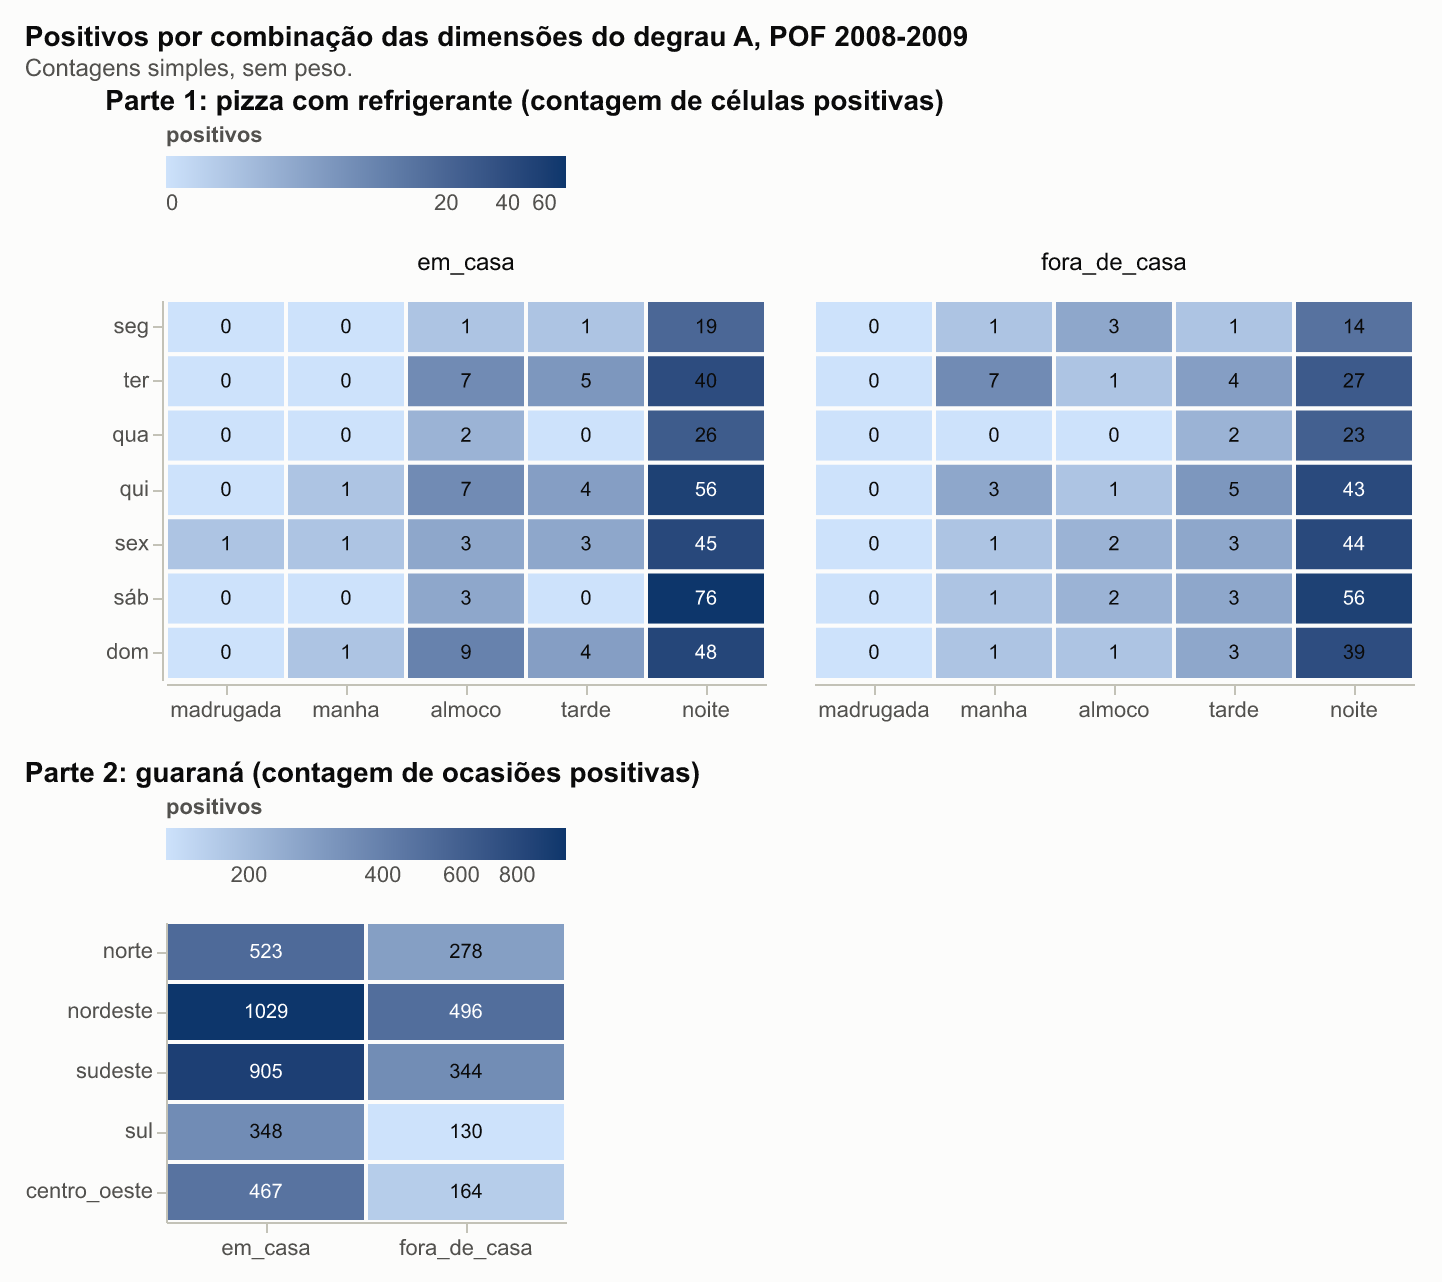

In [23]:
def esparsidade(base: pd.DataFrame, alvo: str, dimensoes: list[str]) -> pd.DataFrame:
    dominios = [sorted(base[d].astype(str).unique()) for d in dimensoes]
    completo = pd.MultiIndex.from_product(dominios, names=dimensoes)
    t = base.assign(**{d: base[d].astype(str) for d in dimensoes}).groupby(dimensoes)
    return (
        pd.DataFrame(
            {
                "n": t.size().reindex(completo, fill_value=0),
                "positivos": t[alvo].sum().reindex(completo, fill_value=0),
            }
        )
        .astype(int)
        .reset_index()
    )


esp1 = esparsidade(celulas, "y_pizza_refri", DIMENSOES_PARTE_1)
esp2 = esparsidade(refri, "y_guarana", DIMENSOES_PARTE_2)
esp1["dia"] = esp1["dia_semana"].map(lambda d: DIAS[int(d) - 1])


def resumo_esparsidade(t: pd.DataFrame) -> dict[str, Any]:
    p = t["positivos"]
    return {
        "combinacoes": len(t),
        "sem_positivo": int((p == 0).sum()),
        "menos_de_5": int((p < 5).sum()),
        "menos_de_10": int((p < 10).sum()),
        "menos_de_30": int((p < 30).sum()),
        "mediana": float(p.median()),
        "maximo": int(p.max()),
    }


eda["degrau_a"] = {
    "parte_1": {
        "dimensoes": DIMENSOES_PARTE_1,
        "resumo": resumo_esparsidade(esp1),
        "positivos_por_combinacao": esp1[[*DIMENSOES_PARTE_1, "n", "positivos"]].to_dict(
            orient="records"
        ),
    },
    "parte_2": {
        "dimensoes": DIMENSOES_PARTE_2,
        "resumo": resumo_esparsidade(esp2),
        "positivos_por_combinacao": esp2[[*DIMENSOES_PARTE_2, "n", "positivos"]].to_dict(
            orient="records"
        ),
    },
}

mapa1 = (
    (
        alt.Chart(esp1)
        .mark_rect(stroke=SUPERFICIE, strokeWidth=2)
        .encode(
            x=alt.X("faixa_horario:N", sort=ORDEM_FAIXAS, title=None, axis=alt.Axis(labelAngle=0)),
            y=alt.Y("dia:N", sort=DIAS, title=None),
            color=alt.Color(
                "positivos:Q",
                scale=alt.Scale(range=["#cde2fb", "#0d366b"], type="symlog"),
                title="positivos",
            ),
        )
        + alt.Chart(esp1)
        .mark_text(fontSize=10)
        .encode(
            x=alt.X("faixa_horario:N", sort=ORDEM_FAIXAS),
            y=alt.Y("dia:N", sort=DIAS),
            text="positivos:Q",
            color=alt.condition("datum.positivos > 40", alt.value("#ffffff"), alt.value(TINTA)),
        )
    )
    .properties(width=300, height=190)
    .facet(column=alt.Column("local:N", title=None, sort=["em_casa", "fora_de_casa"]))
    .properties(title=alt.Title("Parte 1: pizza com refrigerante (contagem de células positivas)"))
)
mapa2 = (
    alt.Chart(esp2)
    .mark_rect(stroke=SUPERFICIE, strokeWidth=2)
    .encode(
        x=alt.X(
            "local:N", sort=["em_casa", "fora_de_casa"], title=None, axis=alt.Axis(labelAngle=0)
        ),
        y=alt.Y("regiao:N", sort=VARIAVEIS["regiao"][1], title=None),
        color=alt.Color(
            "positivos:Q",
            scale=alt.Scale(range=["#cde2fb", "#0d366b"], type="symlog"),
            title="positivos",
        ),
    )
    + alt.Chart(esp2)
    .mark_text(fontSize=10)
    .encode(
        x=alt.X("local:N", sort=["em_casa", "fora_de_casa"]),
        y=alt.Y("regiao:N", sort=VARIAVEIS["regiao"][1]),
        text="positivos:Q",
        color=alt.condition("datum.positivos > 400", alt.value("#ffffff"), alt.value(TINTA)),
    )
).properties(width=200, height=150, title="Parte 2: guaraná (contagem de ocasiões positivas)")
alt.vconcat(mapa1, mapa2).resolve_scale(color="independent").properties(
    title=alt.Title(
        "Positivos por combinação das dimensões do degrau A, POF 2008-2009",
        subtitle="Contagens simples, sem peso.",
    )
)

In [24]:
# Só para informar o autor: a mesma contagem com outras dimensões possíveis para a parte 1.
# Nada aqui muda DIMENSOES_PARTE_1.
celulas["grupo_dia"] = np.where(fds, "sex-dom", "seg-qui")
alternativas = {
    "grupo_dia x faixa_horario x local": ["grupo_dia", "faixa_horario", "local"],
    "faixa_horario x local": ["faixa_horario", "local"],
    "dia_semana x local (só noite)": ["dia_semana", "local"],
}
resumo_alt = {}
for nome, dims in alternativas.items():
    base_alt = celulas[noite] if "só noite" in nome else celulas
    resumo_alt[nome] = resumo_esparsidade(esparsidade(base_alt, "y_pizza_refri", dims))
eda["degrau_a"]["parte_1"]["alternativas_descritivas"] = resumo_alt
display(pd.DataFrame(resumo_alt).T)

r1, r2 = eda["degrau_a"]["parte_1"]["resumo"], eda["degrau_a"]["parte_2"]["resumo"]
ra = resumo_alt["grupo_dia x faixa_horario x local"]
leitura(
    f"Na parte 1, das {r1['combinacoes']} combinações de dia, faixa e local, {r1['sem_positivo']} "
    f"não têm nenhum positivo, {r1['menos_de_10']} têm menos de 10 e {r1['menos_de_30']} têm "
    f"menos de 30 (mediana de {dec(r1['mediana'], 1)}, máximo de {r1['maximo']}). Na parte 2, as "
    f"{r2['combinacoes']} combinações de região e local têm de {int(esp2['positivos'].min())} a "
    f"{r2['maximo']} positivos ({r2['menos_de_30']} com menos de 30). Só como referência, "
    f"juntar os dias em seg-qui e sex-dom deixaria {ra['combinacoes']} combinações, "
    f"{ra['sem_positivo']} sem positivo e {ra['menos_de_10']} com menos de 10."
)

,combinacoes,sem_positivo,menos_de_5,menos_de_10,menos_de_30,mediana,maximo
grupo_dia x faixa_horario x local,20.0,3.0,7.0,11.0,16.0,8.0,169.0
faixa_horario x local,10.0,1.0,3.0,3.0,7.0,15.5,310.0
dia_semana x local (só noite),14.0,0.0,0.0,0.0,5.0,41.5,76.0


**Leitura.** Na parte 1, das 70 combinações de dia, faixa e local, 21 não têm nenhum positivo, 56 têm menos de 10 e 61 têm menos de 30 (mediana de 1,5, máximo de 76). Na parte 2, as 10 combinações de região e local têm de 130 a 1029 positivos (0 com menos de 30). Só como referência, juntar os dias em seg-qui e sex-dom deixaria 20 combinações, 3 sem positivo e 11 com menos de 10.

## Gravação de `reports/eda.json`

In [25]:
def _json(obj: Any) -> Any:
    if isinstance(obj, dict):
        return {str(k): _json(v) for k, v in obj.items()}
    if isinstance(obj, list | tuple):
        return [_json(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating | float):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


saida = RELATORIOS / "eda.json"
saida.write_text(json.dumps(_json(eda), ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"gravado: {saida.relative_to(RAIZ)} ({len(saida.read_text(encoding='utf-8')):,} caracteres)")

gravado: reports/eda.json (119,196 caracteres)
